In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import zscore
import math
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, f1_score, precision_score, recall_score, precision_recall_curve,roc_curve,roc_auc_score
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier

In [2]:
# Helper functions
def plot_hist_and_boxplot(data, cols, hue=None):
    """
    Plots a histogram and a corresponding box plot for a list of columns.
    
    Args:
        data (pd.DataFrame): The input pandas DataFrame.
        cols (list): A list of numerical column names to plot.
        hue (str, optional): Categorical column name to group and color the data.
    """
    n_rows = len(cols)
    
    if n_rows == 0:
        print("Error: The list of columns is empty.")
        return

    # Create subplots: n_rows x 2
    # squeeze=False guarantees 'axes' is a 2D array (e.g., axes[0, 0]), even for 1 row
    fig, axes = plt.subplots(nrows=n_rows, ncols=2, figsize=(12, 4 * n_rows), squeeze=False)
    
    for i, col in enumerate(cols):
        # Set up kwargs to avoid color conflicts if 'hue' is provided
        hist_kwargs = {'hue': hue} if hue else {'color': 'skyblue'}
        box_kwargs = {'hue': hue} if hue else {'color': 'lightgreen'}

        # 1. Histogram on the left (column 0)
        sns.histplot(data=data, x=col, kde=True, ax=axes[i, 0], **hist_kwargs)
        axes[i, 0].set_title(f'Histogram of {col}', fontsize=12)
        axes[i, 0].set_ylabel('Frequency')
        
        # 2. Box plot on the right (column 1)
        sns.boxplot(data=data, x=col, ax=axes[i, 1], **box_kwargs)
        axes[i, 1].set_title(f'Box Plot of {col}', fontsize=12)
        
    # Adjust layout so plots don't overlap
    plt.tight_layout()
    plt.show()

def plot_bar_subplots(df, columns, max_cols=3):
    """
    Plots bar charts for given categorical/discrete columns in subplots.

    Parameters:
    df (pd.DataFrame): Input dataframe
    columns (list): List of column names to plot
    max_cols (int): Max number of subplot columns per row
    """
    
    n = len(columns)
    rows = math.ceil(n / max_cols)
    
    fig, axes = plt.subplots(rows, max_cols, figsize=(5 * max_cols, 4 * rows))
    axes = axes.flatten() if n > 1 else [axes]
    
    for i, col in enumerate(columns):
        # print(i, col)
        ax = axes[i]
        
        # Count values
        value_counts = df[col].value_counts().sort_index()
        
        # Plot
        ax.bar(value_counts.index.astype(str), value_counts.values)
        ax.set_title(f"{col}")
        ax.set_xlabel("Categories")
        ax.set_ylabel("Count")
        ax.tick_params(axis='x', rotation=45)
    
    # Remove empty subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
    
    plt.tight_layout()
    plt.show()

def score(y_pred, y):
    print(f'Accuracy: {accuracy_score(y, y_pred)}')
    print(f'Precision: {precision_score(y, y_pred)}')
    print(f'Recall: {recall_score(y, y_pred)}')
    print(f'F-1 Score: {f1_score(y, y_pred)}')
    print(f'ROC, AUC Score: {roc_auc_score(y, y_pred)}')

def plot_classification_curves(model, X_test, y_test):
    y_probs = model.predict_proba(X_test)[:, 1]

    # =========================
    # Precision-Recall Curve
    # =========================
    precision, recall, thresholds_pr = precision_recall_curve(y_test, y_probs)

    plt.figure()
    plt.plot(recall, precision)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Precision-Recall Curve")
    plt.show()

    # =========================
    # Precision & Recall vs Threshold (NEW 🔥)
    # =========================
    plt.figure()
    plt.plot(thresholds_pr, precision[:-1], label="Precision")
    plt.plot(thresholds_pr, recall[:-1], label="Recall")
    plt.xlabel("Threshold")
    plt.ylabel("Score")
    plt.title("Precision & Recall vs Threshold")
    plt.legend()
    plt.show()

    # =========================
    # F1 vs Threshold
    # =========================
    f1_scores = 2 * (precision * recall) / (precision + recall + 1e-8)

    plt.figure()
    plt.plot(thresholds_pr, f1_scores[:-1])
    plt.xlabel("Threshold")
    plt.ylabel("F1 Score")
    plt.title("F1 Score vs Threshold")
    plt.show()

    # =========================
    # ROC Curve
    # =========================
    fpr, tpr, _ = roc_curve(y_test, y_probs)
    roc_auc = roc_auc_score(y_test, y_probs)

    plt.figure()
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    plt.show()

def plot_confusion_matrix(model, X, y, title="Confusion Matrix", threshold=None):
    if threshold is None:
        y_pred = model.predict(X)
    else:
        y_pred = model.predict_proba(X)[:, 1] >= threshold
    cm = confusion_matrix(y, y_pred)
    
    plt.figure()
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['No Churn', 'Churn'],
        yticklabels=['No Churn', 'Churn']
    )
    
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(title)
    plt.show()
    

In [3]:
data = pd.read_csv('./WA_Fn-UseC_-Telco-Customer-Churn.csv')
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# To Build:

# Customer Churn Model - Part 1
# CUstomer Churn rick segmentation and based upon it a recommender - Part 2

In [5]:
# Checking data info, datatypes

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
# Total Charges is not a object
data['TotalCharges']

0         29.85
1        1889.5
2        108.15
3       1840.75
4        151.65
         ...   
7038     1990.5
7039     7362.9
7040     346.45
7041      306.6
7042     6844.5
Name: TotalCharges, Length: 7043, dtype: object

In [7]:
data['TotalCharges'][488]
# data['TotalCharges']

' '

In [8]:
# FOr now we will keep as 0.0 value

data[(data['TotalCharges'] == ' ')]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [9]:
data['TotalCharges'] = data['TotalCharges'].str.replace(' ', '0.00')

In [10]:
# COnverting, Total Charges to numeric column

data['TotalCharges'] = pd.to_numeric(data['TotalCharges'])

In [11]:
# Checking for Data Issues

In [12]:
# Missing Values

data.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [13]:
# In Total charges we had filled " " as 0.00, lets see how to tackle this

data[data['TotalCharges'] == 0.0]


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,0.0,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,0.0,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,0.0,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,0.0,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,0.0,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,0.0,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,0.0,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,0.0,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,0.0,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,0.0,No


In [14]:
# Now main decsion to take should we drop it or impute it
(11/data.shape[0])*100

0.1561834445548772

In [15]:
#0.15% of the data are these values

In [16]:
# But for these values monthly charges is available

# Lets see if there is any relationship between monthly charges and total charges

test = data[data['TotalCharges'] != 0.0]

In [17]:
test[['tenure', 'Contract','MonthlyCharges', 'TotalCharges']]

,tenure,Contract,MonthlyCharges,TotalCharges
0,1,Month-to-month,29.85,29.85
1,34,One year,56.95,1889.50
2,2,Month-to-month,53.85,108.15
3,45,One year,42.30,1840.75
4,2,Month-to-month,70.70,151.65
...,...,...,...,...
7038,24,One year,84.80,1990.50
7039,72,One year,103.20,7362.90
7040,11,Month-to-month,29.60,346.45
7041,4,Month-to-month,74.40,306.60


In [18]:
# Okay so roughly, for month-to-month customers, tenure * month_charges can give us Total charges

In [19]:
# Lets test the relationship
month_to_month = test[test['Contract'] == 'Month-to-month']

(array([1.000e+00, 1.200e+01, 5.900e+01, 2.720e+02, 2.303e+03, 1.011e+03,
        1.770e+02, 3.200e+01, 7.000e+00, 1.000e+00]),
 array([-354.05, -281.32, -208.59, -135.86,  -63.13,    9.6 ,   82.33,
         155.06,  227.79,  300.52,  373.25]),
 <BarContainer object of 10 artists>)

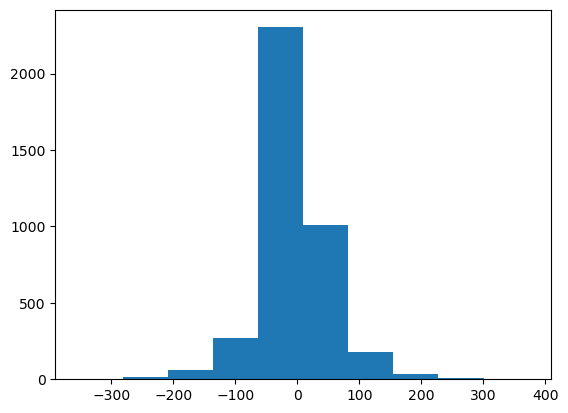

In [20]:
plt.hist(month_to_month['TotalCharges'] - (month_to_month['MonthlyCharges'] * month_to_month['tenure']))

(array([2076.,  615.,  388.,  270.,  178.,  124.,  111.,   63.,   43.,
           7.]),
 array([  18.85 ,  823.115, 1627.38 , 2431.645, 3235.91 , 4040.175,
        4844.44 , 5648.705, 6452.97 , 7257.235, 8061.5  ]),
 <BarContainer object of 10 artists>)

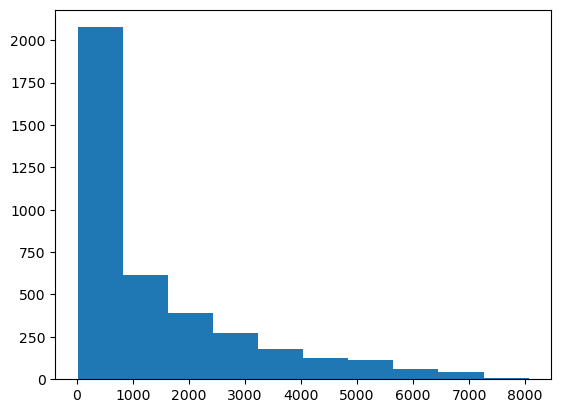

In [21]:
plt.hist(month_to_month['TotalCharges'])

In [22]:
# So we can impute, for month-to-month customers as tenure * monthly charges

In [23]:
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [24]:
# But the rows with missing total charges have tenure as zero, mean that they are new customers
# We can use them as test data and store them seperately

new_customers = (data[data['tenure'] == 0]).reset_index(drop=True)

new_customers.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,0.0,No
1,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,0.0,No
2,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,0.0,No
3,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,0.0,No
4,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,0.0,No


In [25]:
list(data[data['tenure'] == 0].index)

[488, 753, 936, 1082, 1340, 3331, 3826, 4380, 5218, 6670, 6754]

In [26]:
data = (data.drop(index=list(data[data['tenure'] == 0].index))).reset_index(drop=True)

In [27]:
data

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7027,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7028,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7029,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7030,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


In [28]:
target = 'Churn'
numerical_columns = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
dis_object_columns = ['SeniorCitizen', 'customerID', 'gender', 'Partner', 'Dependents',
       'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'Churn']

In [29]:
# Checking for inconsistent values for discrete and object

for col in dis_object_columns:
    print(f'{col}')
    print(data[col].value_counts(normalize=True))
    print('=====================================')

SeniorCitizen
SeniorCitizen
0    0.8376
1    0.1624
Name: proportion, dtype: float64
customerID
customerID
3186-AJIEK    0.000142
7590-VHVEG    0.000142
5575-GNVDE    0.000142
3668-QPYBK    0.000142
7795-CFOCW    0.000142
                ...   
8091-TTVAX    0.000142
7469-LKBCI    0.000142
9763-GRSKD    0.000142
6388-TABGU    0.000142
7892-POOKP    0.000142
Name: proportion, Length: 7032, dtype: float64
gender
gender
Male      0.504693
Female    0.495307
Name: proportion, dtype: float64
Partner
Partner
No     0.517491
Yes    0.482509
Name: proportion, dtype: float64
Dependents
Dependents
No     0.701507
Yes    0.298493
Name: proportion, dtype: float64
PhoneService
PhoneService
Yes    0.903299
No     0.096701
Name: proportion, dtype: float64
MultipleLines
MultipleLines
No                  0.481371
Yes                 0.421928
No phone service    0.096701
Name: proportion, dtype: float64
InternetService
InternetService
Fiber optic    0.440273
DSL            0.343572
No             0.2161

In [30]:
# Gender - Male (50%), Female (50%)
# Senior Citizen - 0 (84%), 1 (16%)
# Partner No-(51%), Yes-(48%)
# Dependents No-(70%), Yes-(30%)
# PhoneService - Yes - (90%), No - (10%)
# Multiple Lines Yes- (42%), No-(48%), No-Phone Service('10%')
# InternetService - Fibre Optic - 44%, DSL-34%, No-21%
# Online Security - No(49%), Yes(28%), No internet service (21%)

# Others also have mild deifferences in them

In [31]:
# Now lets check for

data[data.duplicated(keep=False)]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


In [32]:
# No duplicate values

In [33]:
# Check for outliers

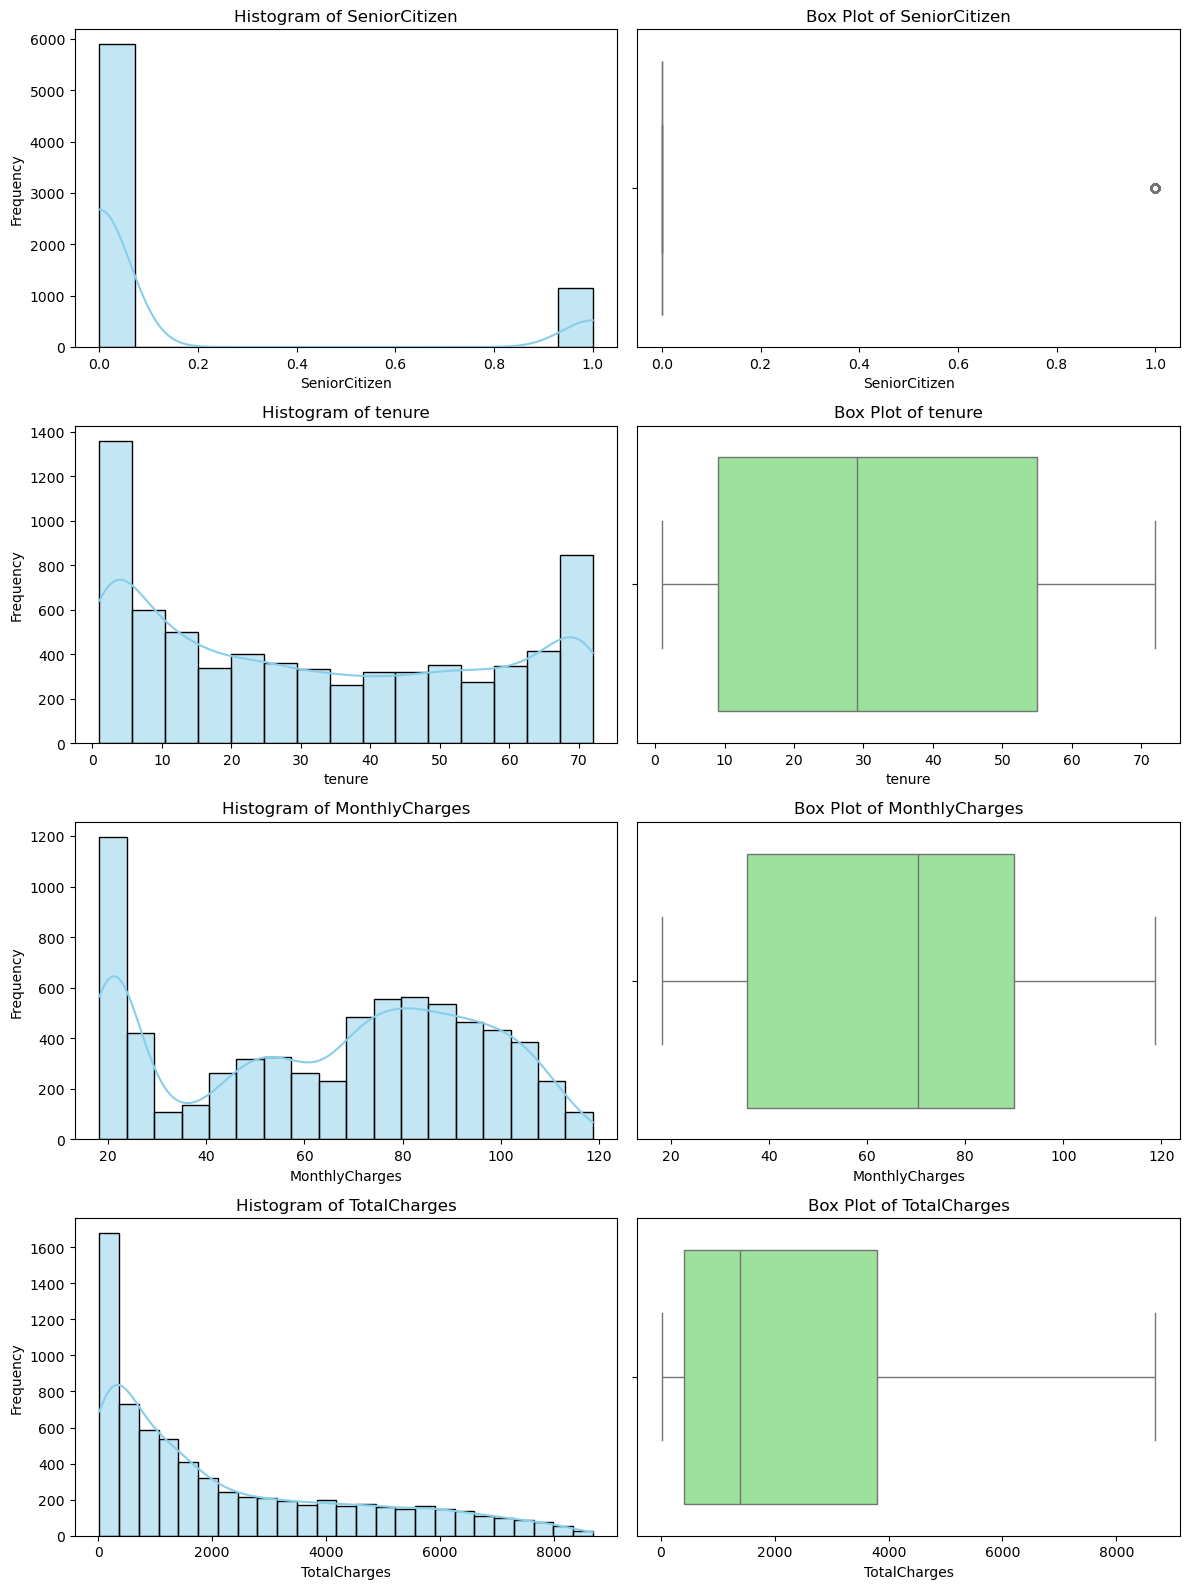

In [34]:
plot_hist_and_boxplot(data, numerical_columns)

In [35]:
data[((zscore(data['tenure']) > 3) | (zscore(data['tenure']) < -3) )]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


In [36]:
data[((zscore(data['MonthlyCharges']) > 3) | (zscore(data['MonthlyCharges']) < -3) )]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


In [37]:
data[((zscore(data['TotalCharges']) < -3))]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


In [38]:
data

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7027,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7028,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7029,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7030,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


In [39]:
# EDA

In [40]:
# Exploting Target

data['Churn'].value_counts(normalize=True)

Churn
No     0.734215
Yes    0.265785
Name: proportion, dtype: float64

<Axes: xlabel='Churn'>

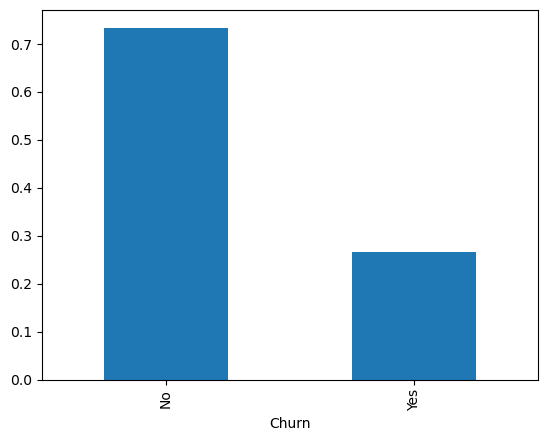

In [41]:
data['Churn'].value_counts(normalize=True).plot.bar()

In [42]:
# There is an imbalance but we can tackle that later

In [43]:
# Exploring Features
# Discrete, Categorical
dis_object_columns

['SeniorCitizen',
 'customerID',
 'gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'Churn']

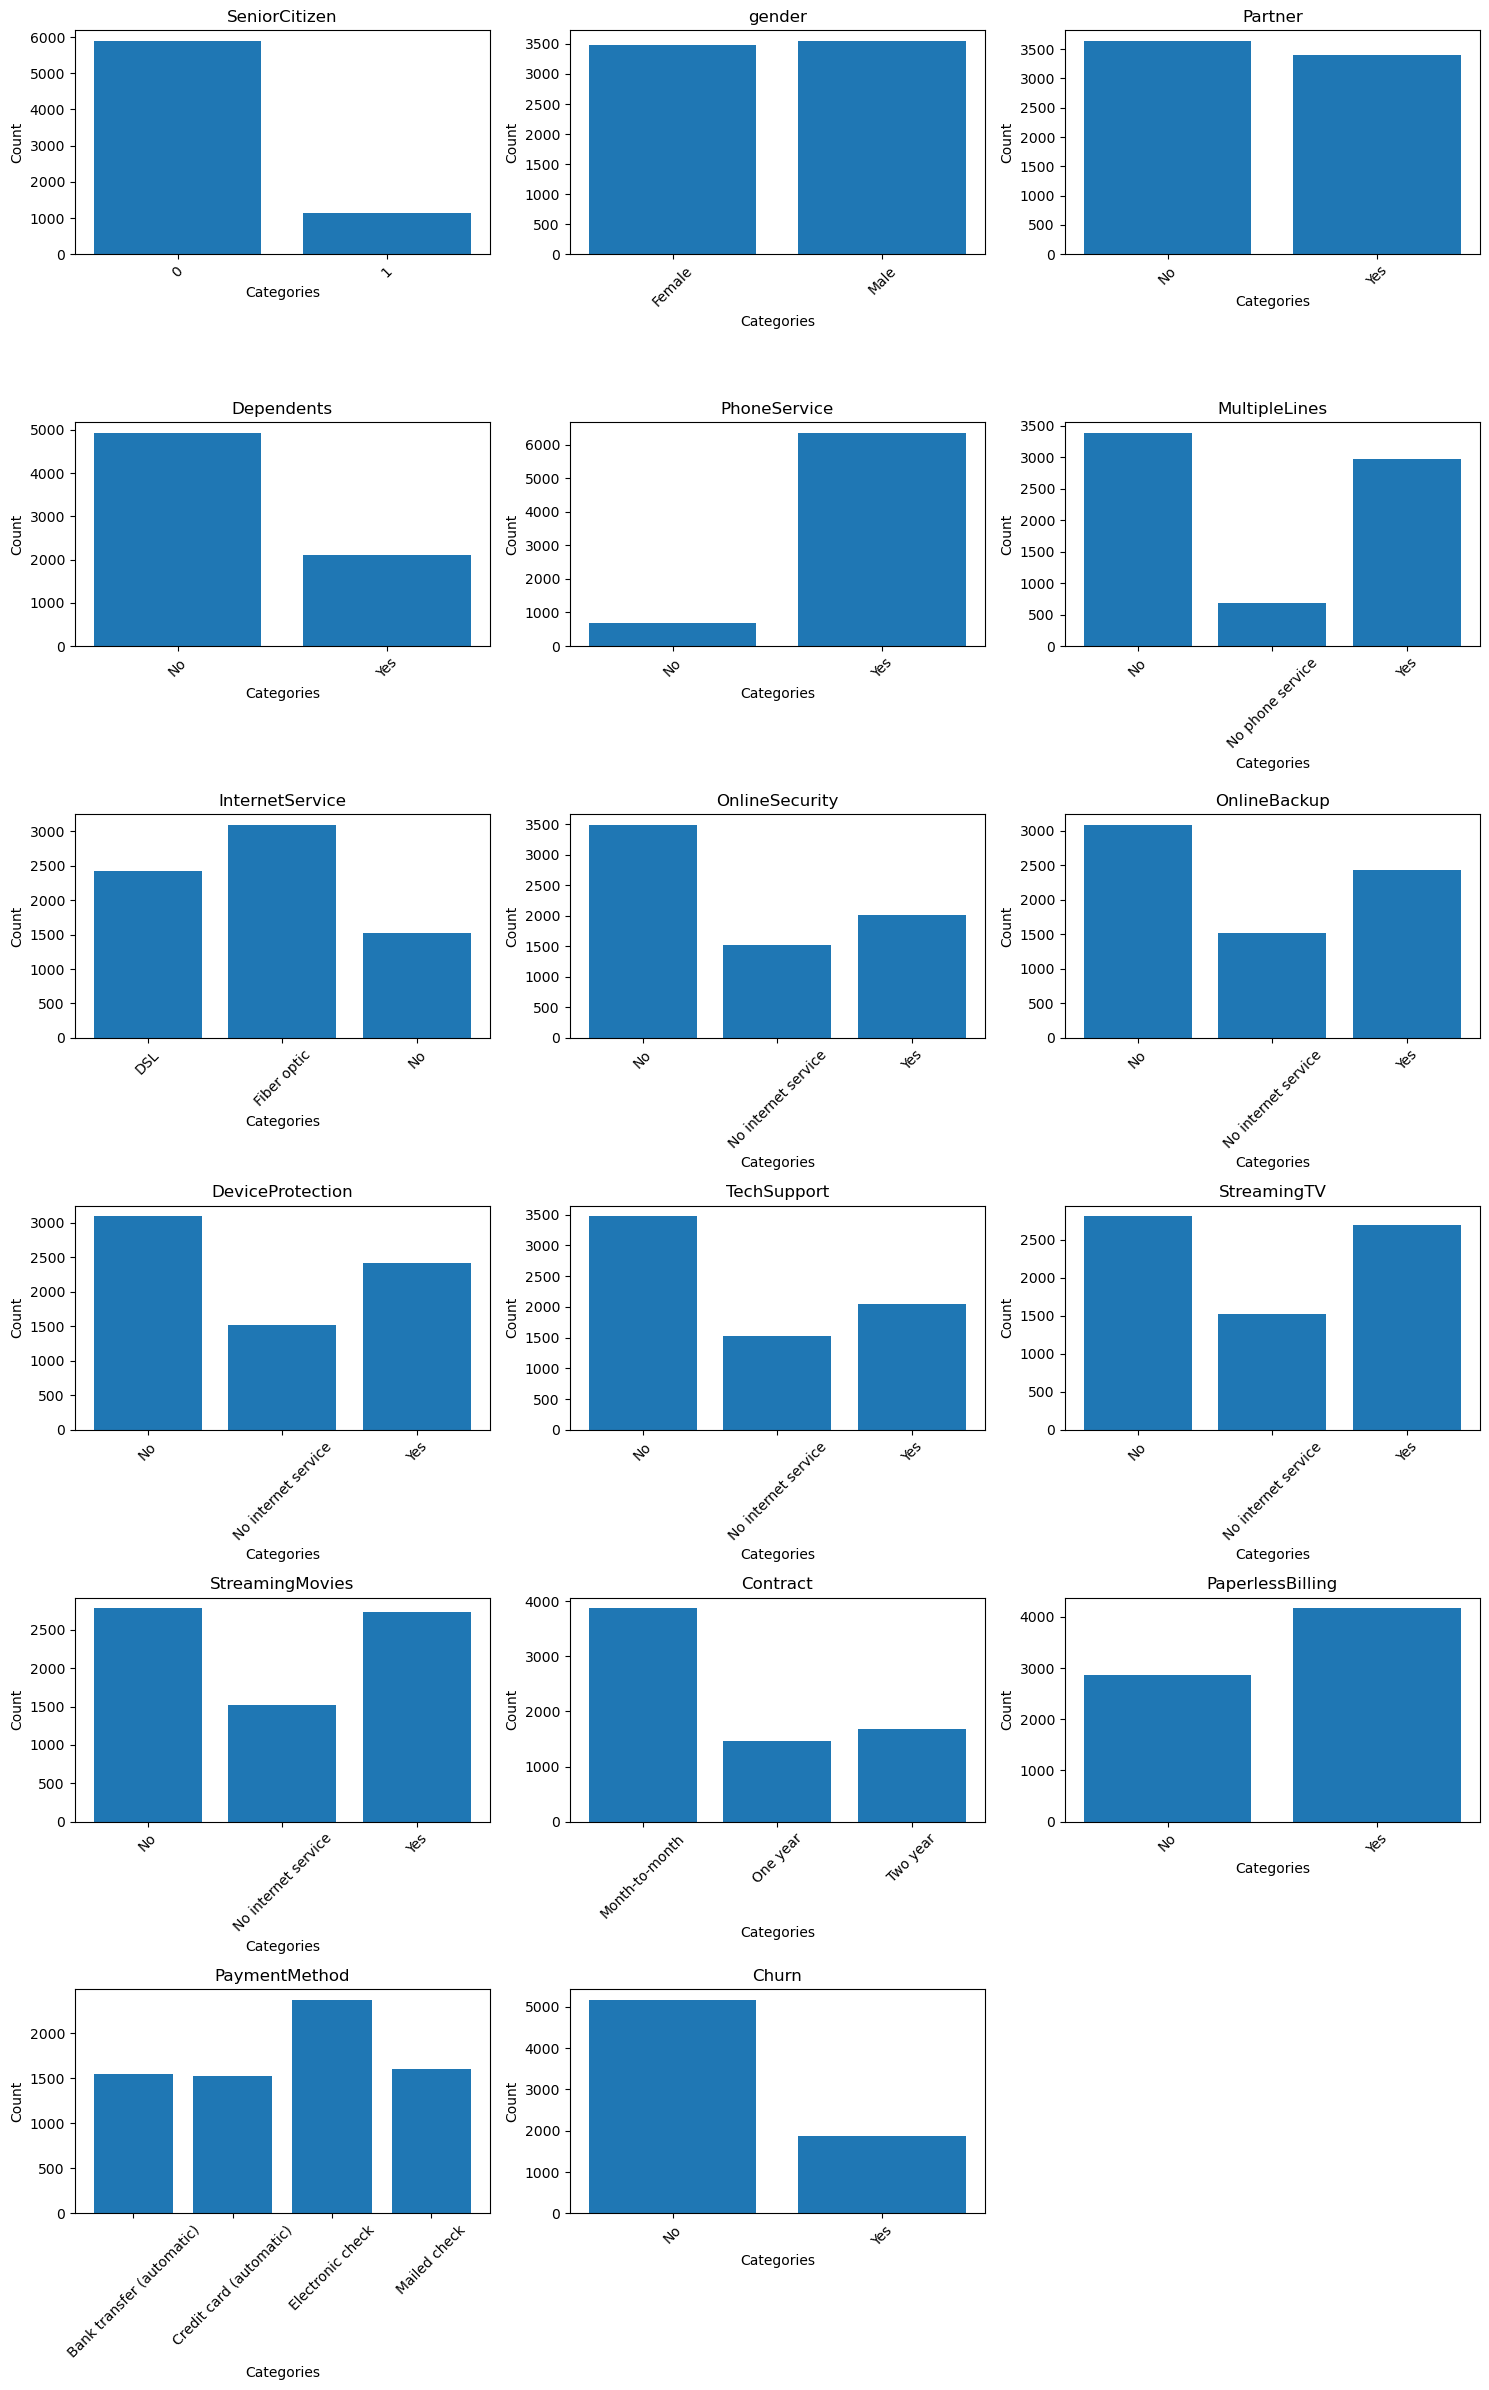

In [44]:
plot_bar_subplots(data, ['SeniorCitizen',
 'gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'Churn'])

In [45]:
# Seperation for Senior Citizen  - <>
# Equally dist gender
# Partner also almost eually dist
# Seperation for Dependents - <>
# Speration for Phone Service - <>
# Speration for 'MultipleLines' - <> can add interation term
# Seperation for InternetService - <>
# Sepeartion for Online Service - <> can add inetration term
# Forlamost other there is seperation

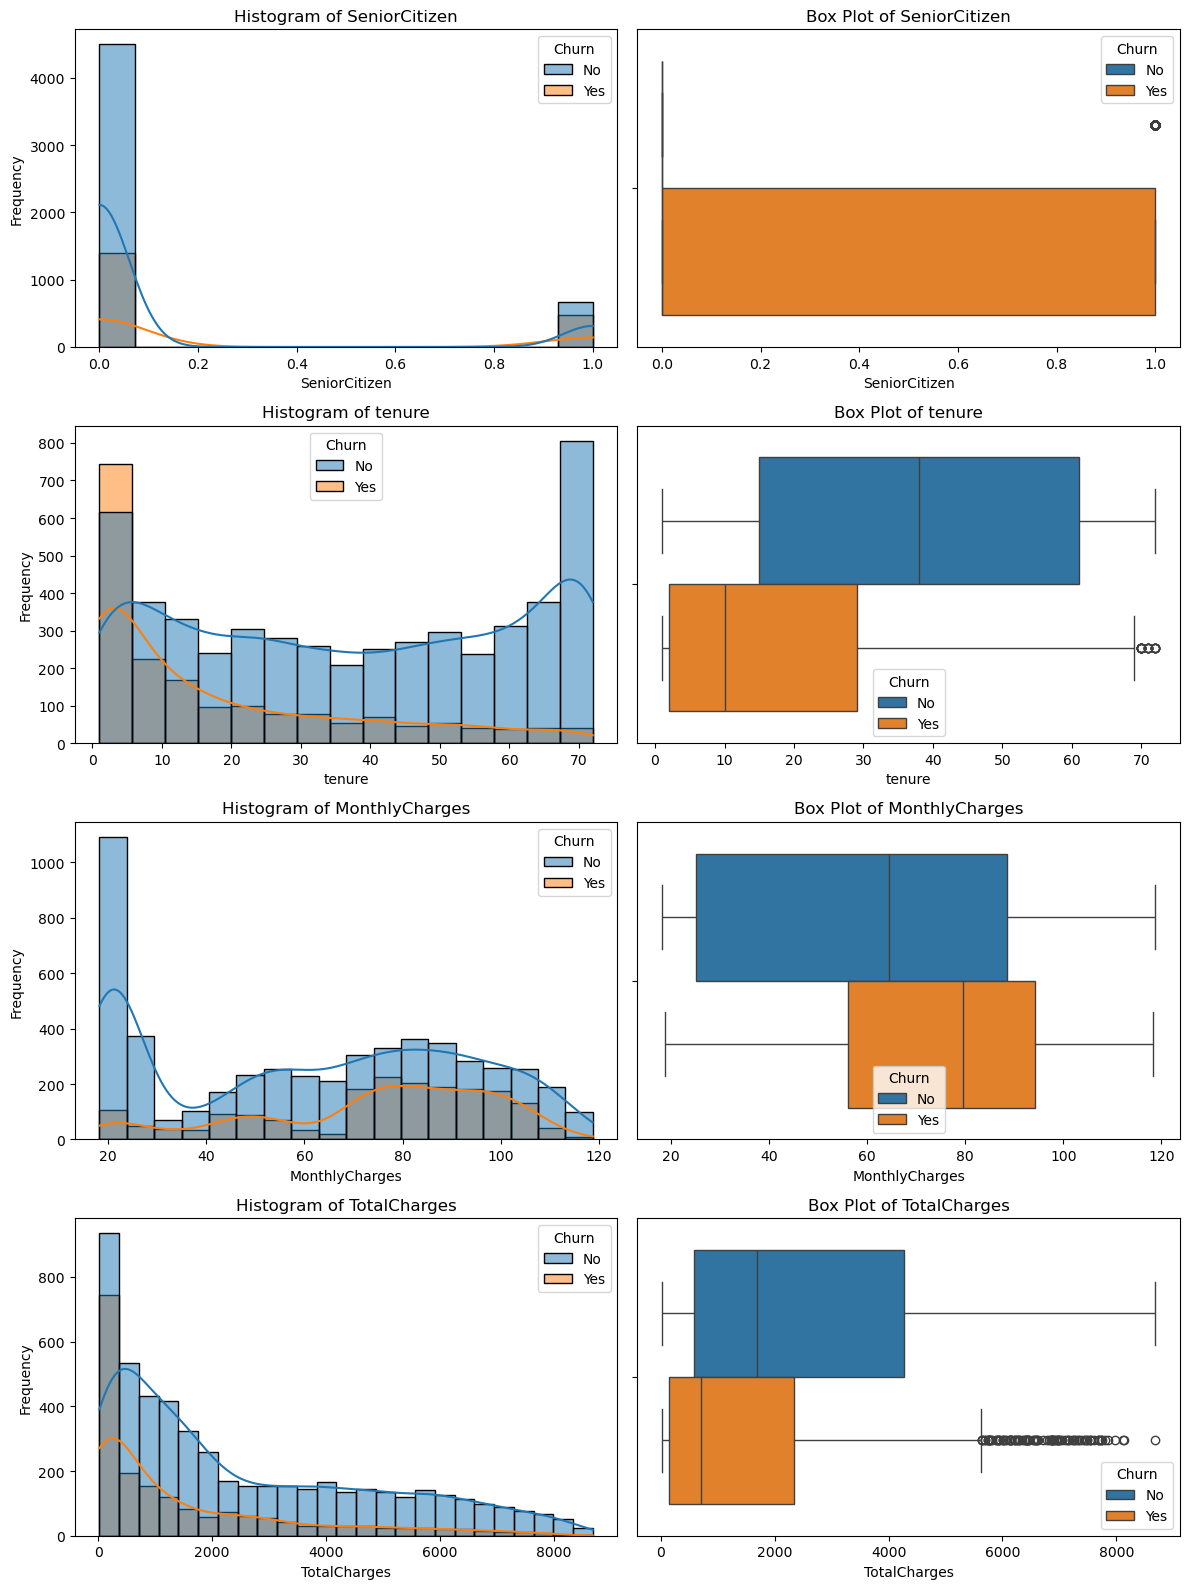

In [46]:
# Exploring Numerical features

plot_hist_and_boxplot(data, numerical_columns, hue='Churn')

In [47]:
# For Senior Citizen, when 0 the relative churn is comparatively low as compared to senio citizen = 1
# Most of the churns are around 0 - 25 months
# In monthly charges, those you have churned have a little higher monthly charge
# But the tottal chage is opposite


# Given this we can understand that 

# Most of the senior citizens churn --> Means most of the senior citizens didnt like the product.
# Furthur seeing tenure we can say there are two types of churn,
# 1) most churns happen within 0 - 30 months
# 2) Long term members churning

# Who had a higher monthly charge they have churned.


In [48]:
# Exploring Feature - Target Relationship
# Numerical Done
# Categorical 

dis_object_columns

['SeniorCitizen',
 'customerID',
 'gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'Churn']

In [49]:
# Lets map CHurn to 1, 0
data['Churn'] = data['Churn'].map({
    'Yes': 1,
    'No': 0
})

In [50]:
data['Churn'].value_counts()

Churn
0    5163
1    1869
Name: count, dtype: int64

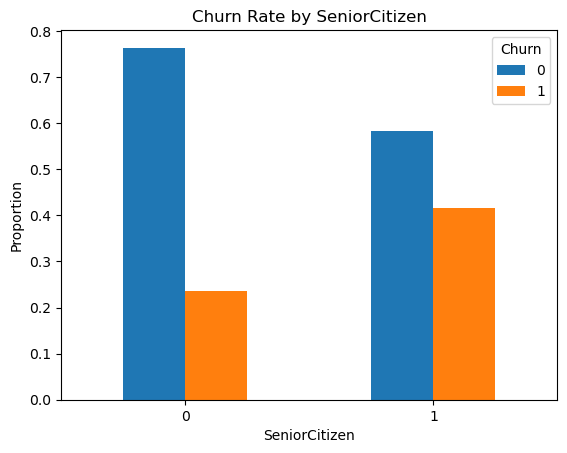

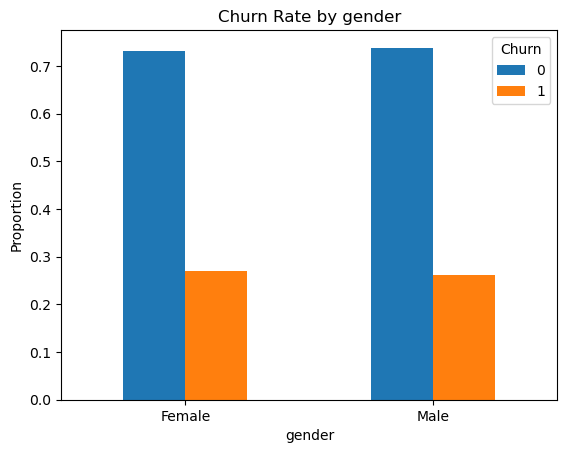

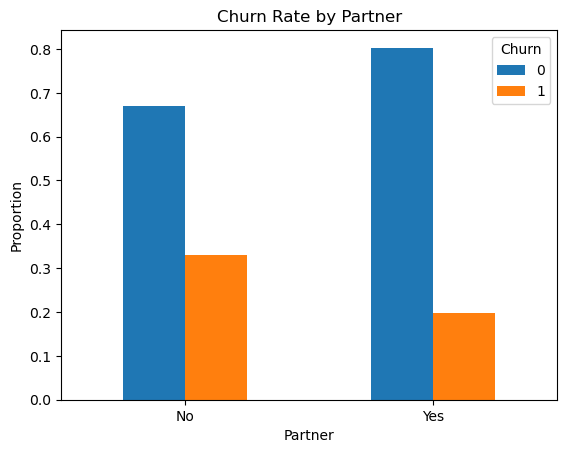

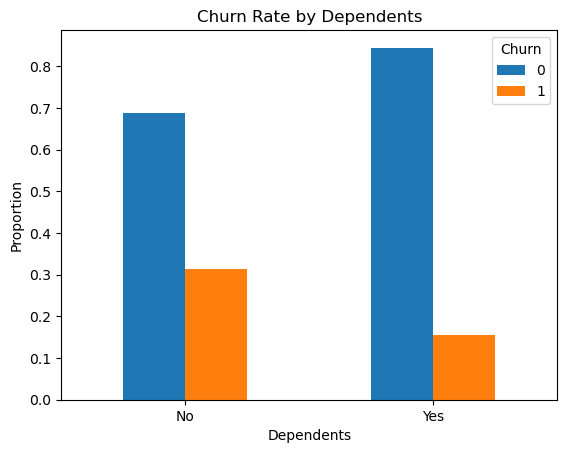

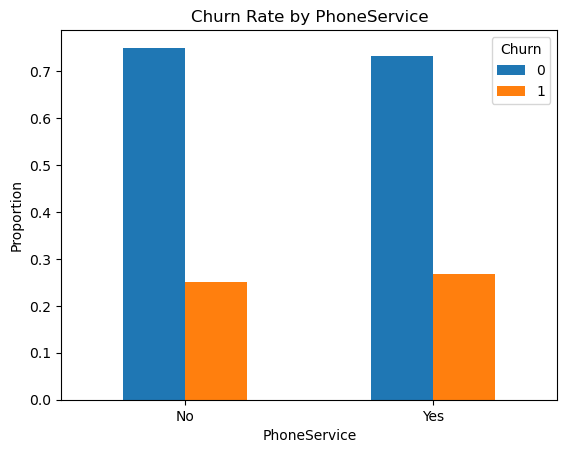

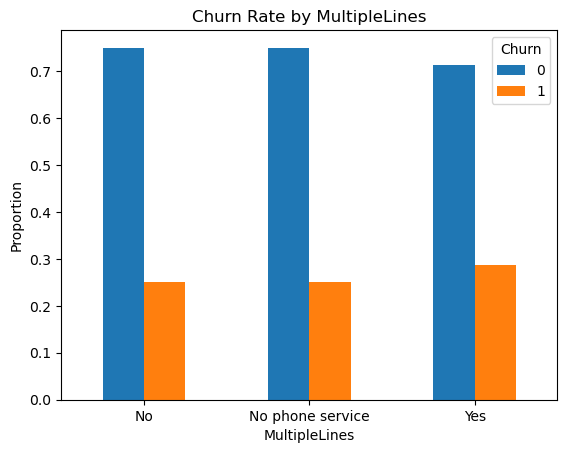

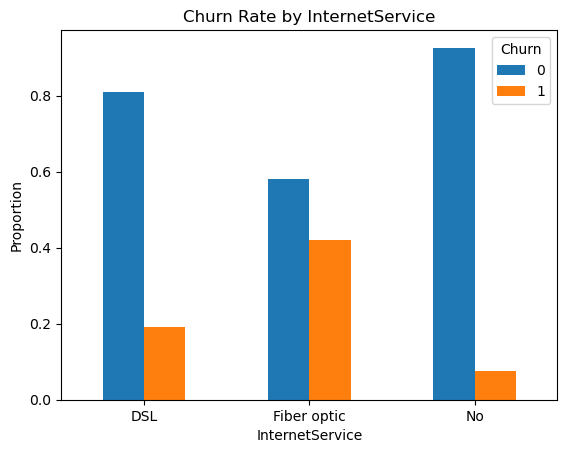

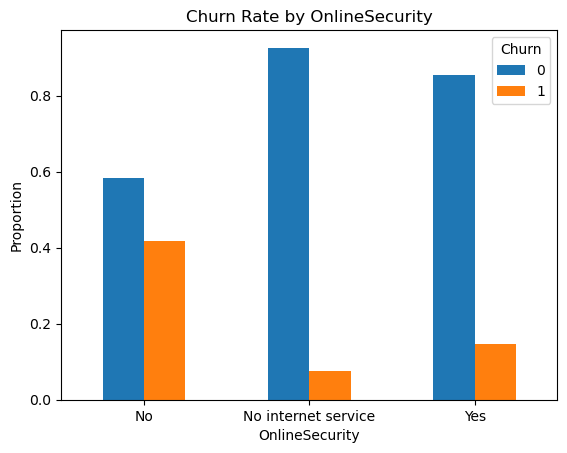

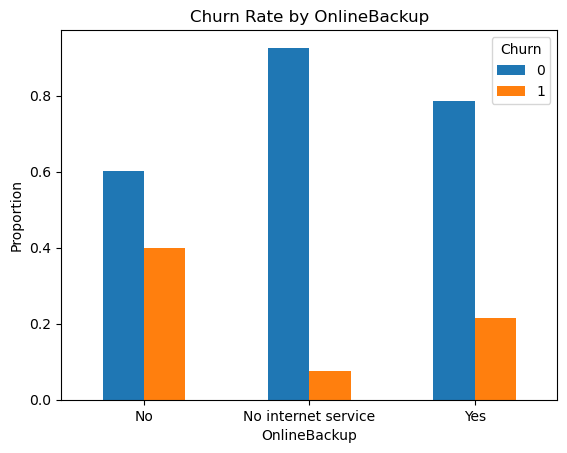

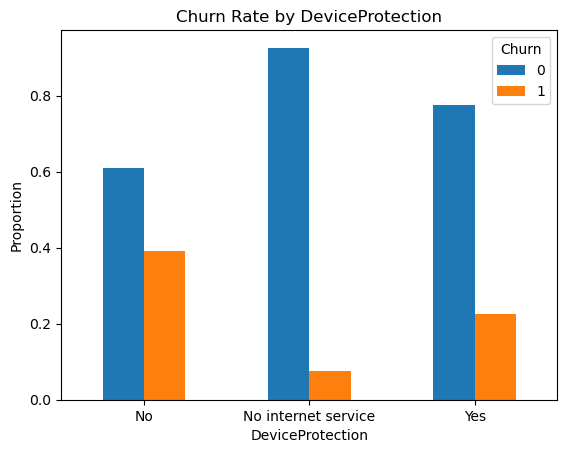

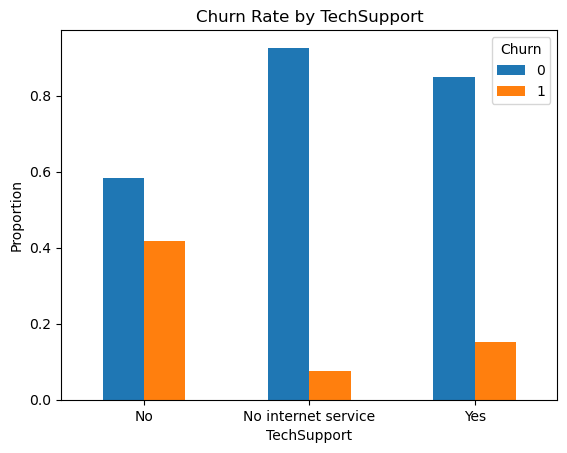

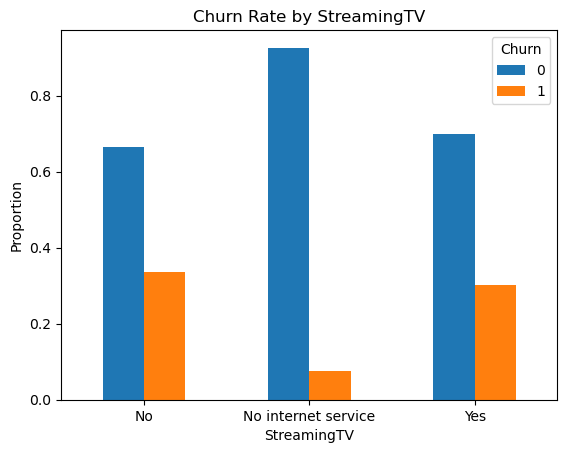

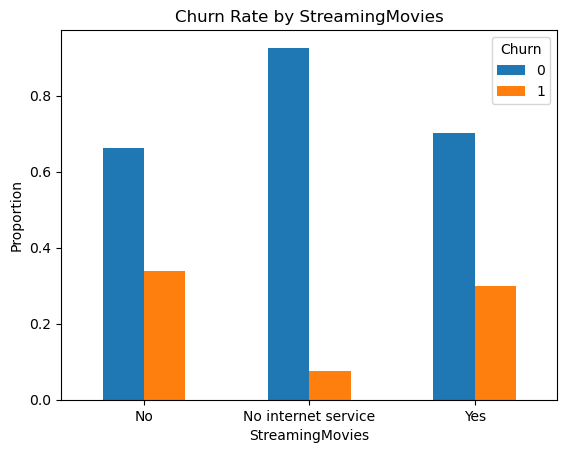

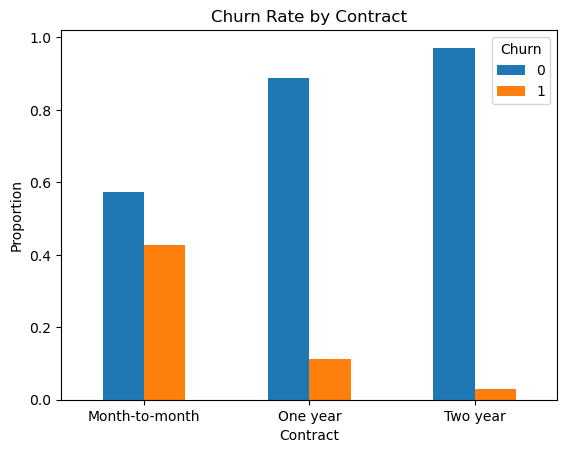

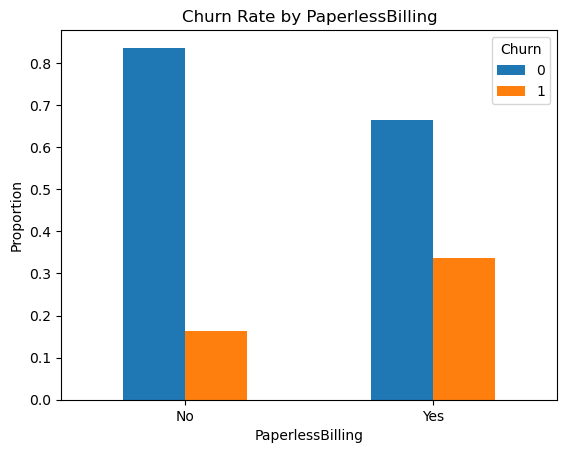

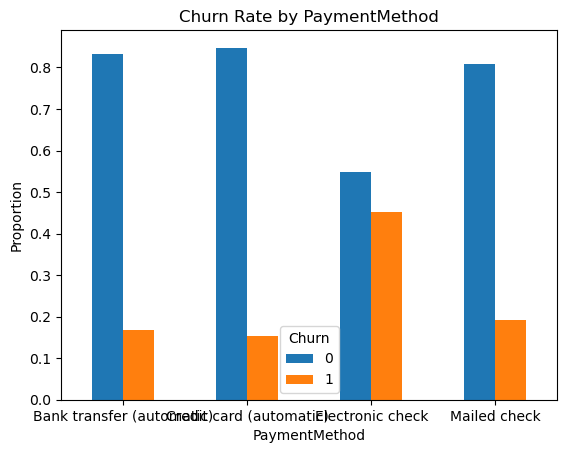

In [51]:
dis_object_columns = ['SeniorCitizen',
 'gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod']

for col in dis_object_columns:
    (data.groupby(col)['Churn']
     .value_counts(normalize=True)
     .unstack()
     .plot(kind='bar'))

    plt.ylabel('Proportion')
    plt.title(f'Churn Rate by {col}')
    plt.xticks(rotation=0)
    plt.show()

<Axes: xlabel='StreamingTV,Churn'>

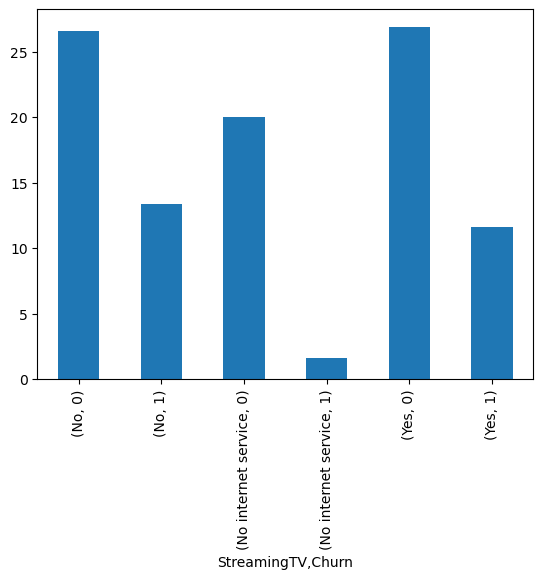

In [52]:
(((data.groupby(['StreamingTV', 'Churn'])['gender'].count())/7032)*100).plot.bar()

In [53]:
# Based on this we can say that

# Within Categories
# MOst of the churns happen from the side of senior citizen
# Gender doesnt provide any useful insight for both the rate is same
# Customers who have a partner tend to churn less
# Semilarly for Dependents
# Those who have a Fibre optic tend to churn more
# Similarly those who dont have online security, techsupport ... (No) tend to churn more
# Customers who have month-to-month contract tend to churn more
# Who have opted for Paperless billing tend to churn more
# Those who have a electron check method, they tend to churn more

In [54]:
data.shape

(7032, 21)

In [55]:
# Globally across a category

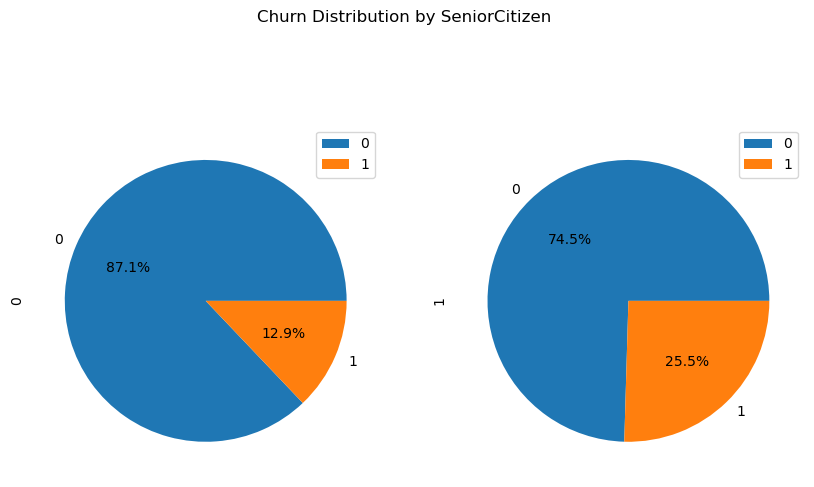

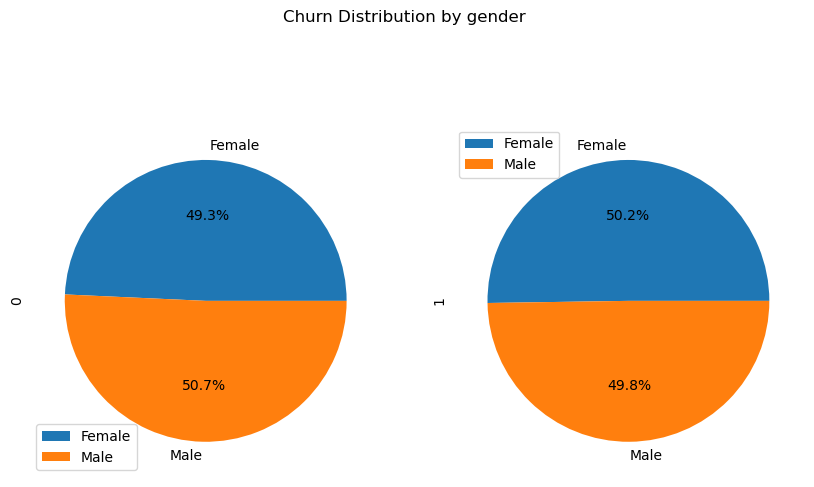

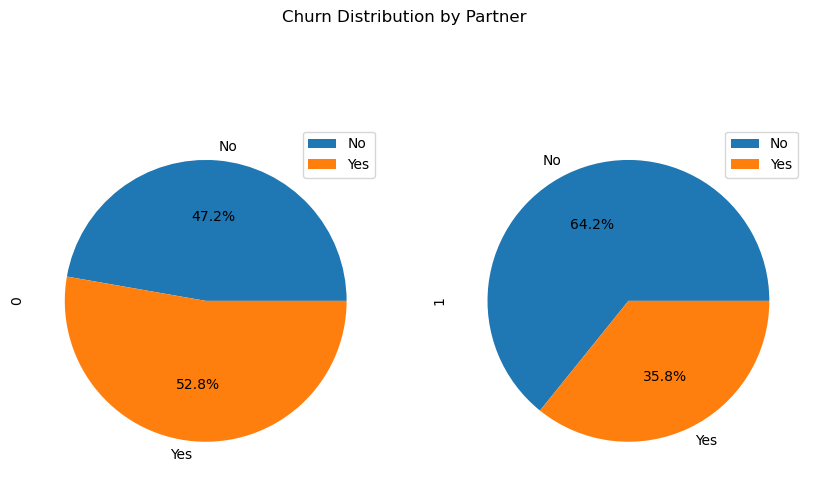

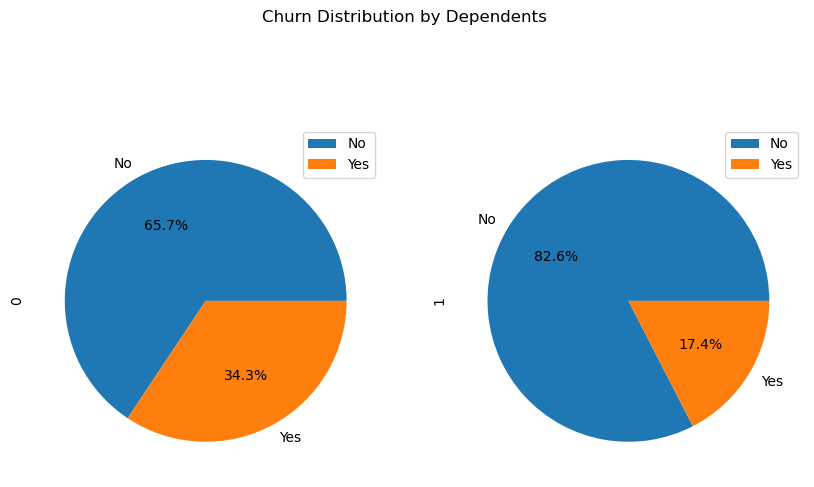

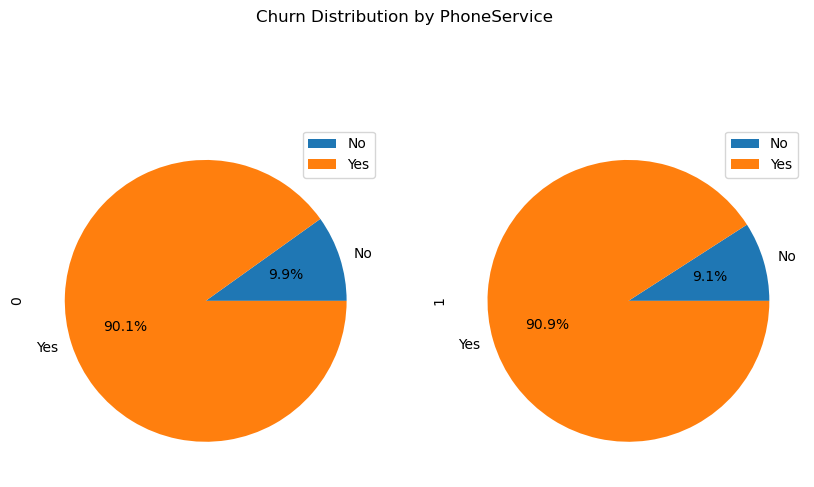

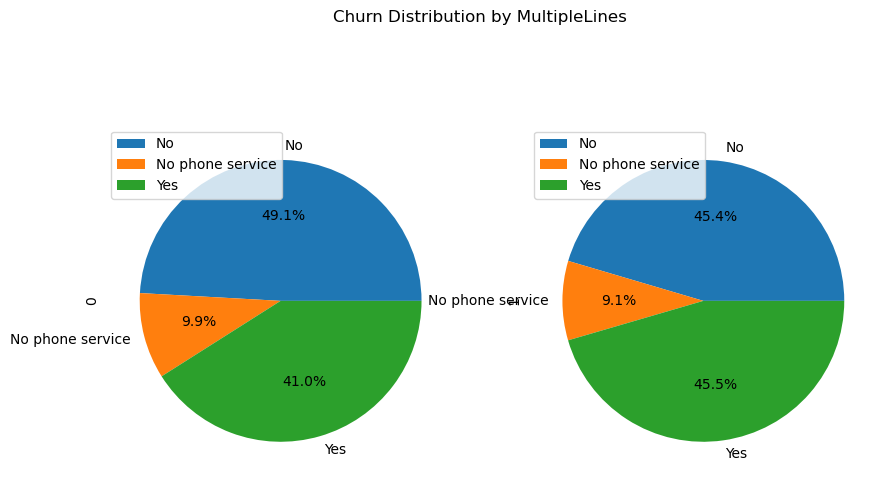

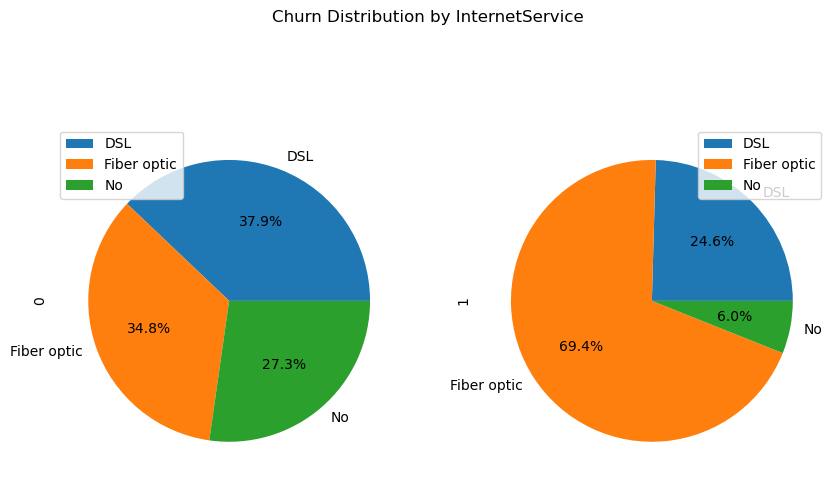

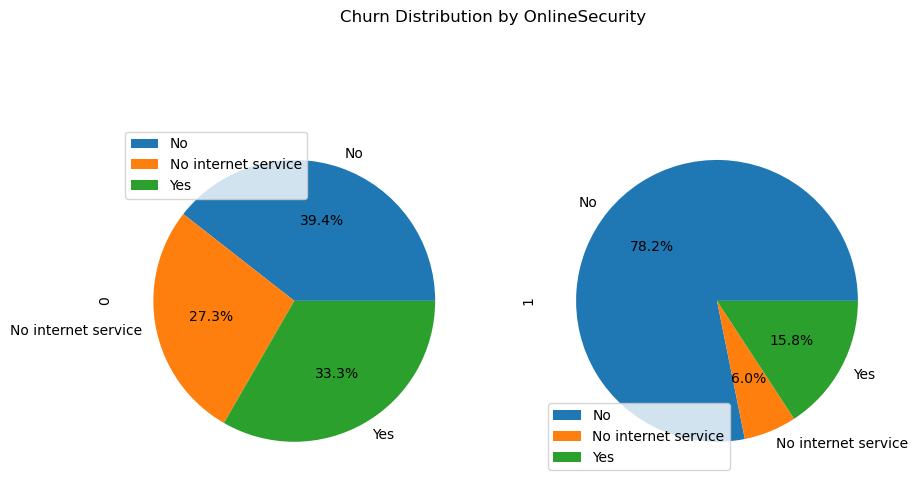

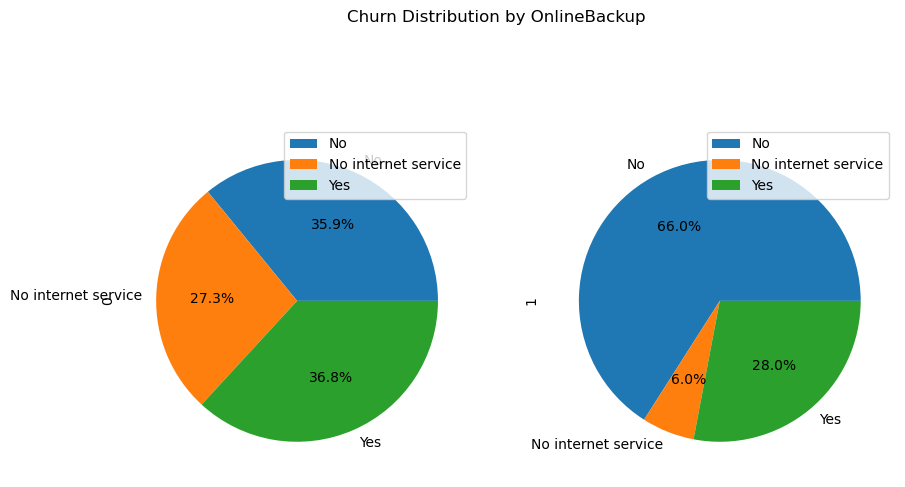

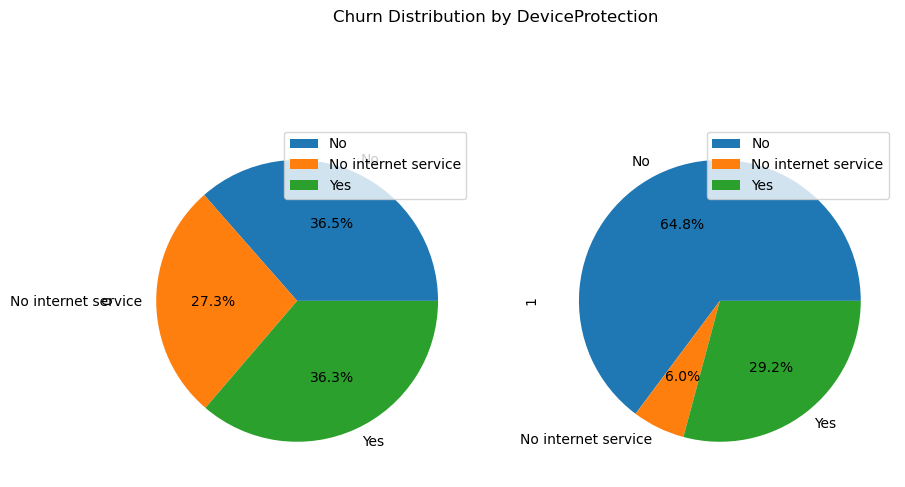

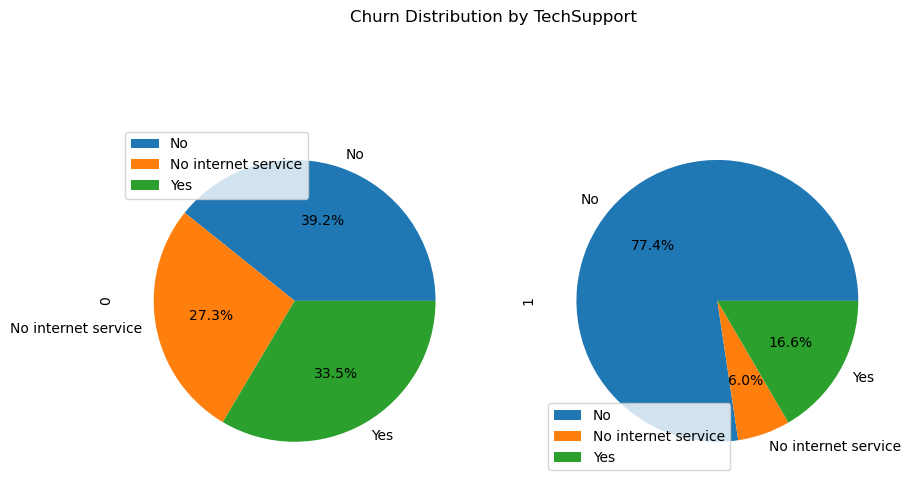

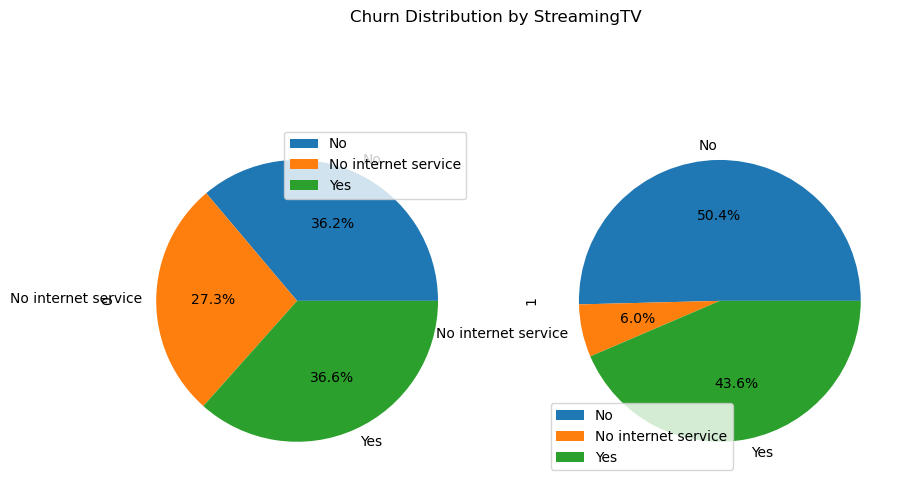

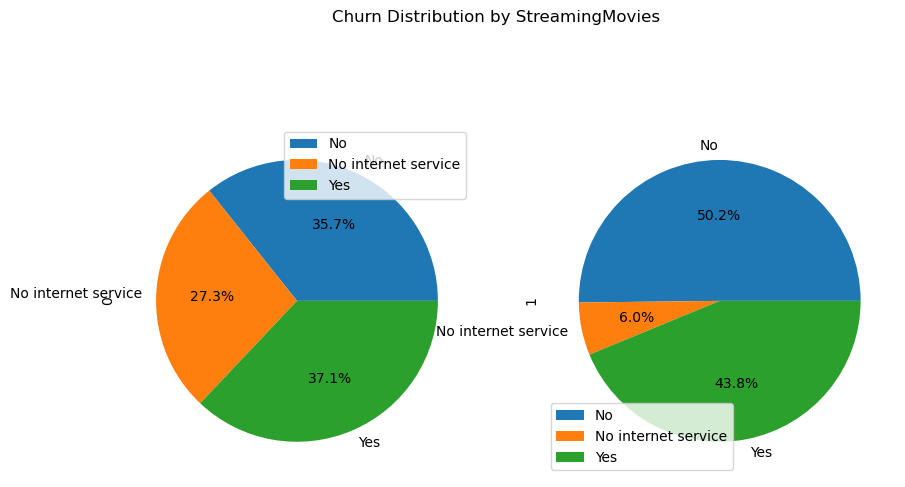

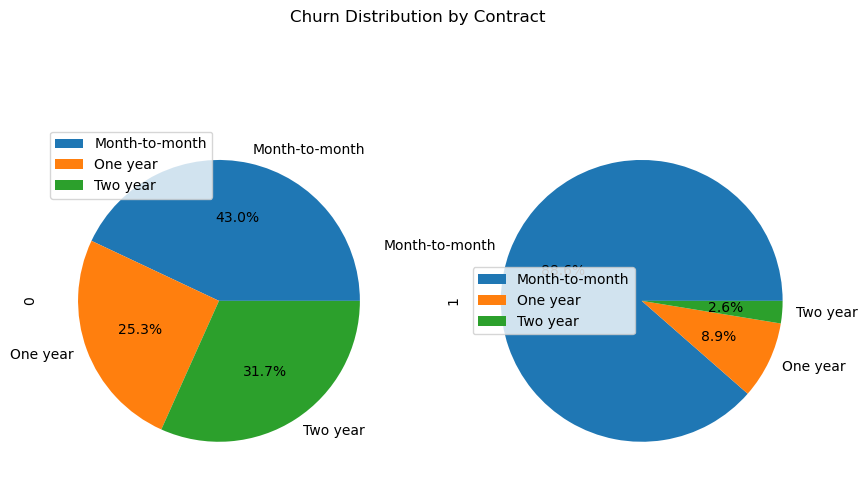

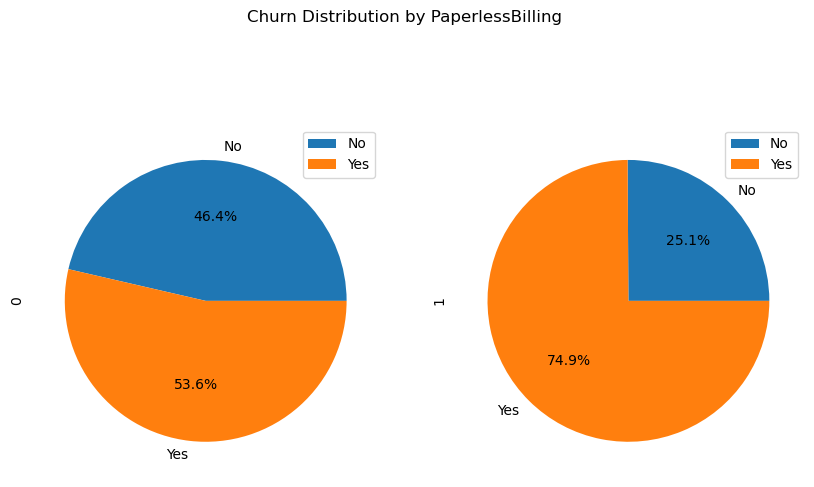

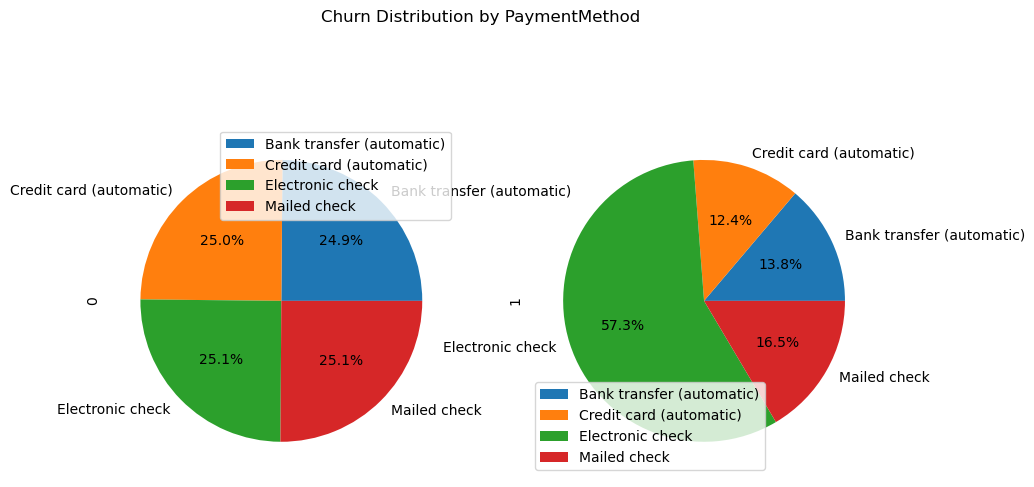

In [56]:
for col in dis_object_columns:
    
    if col == 'Churn':
        continue
    
    result = data.groupby([col, 'Churn']).size().unstack(fill_value=0)
    
    # Plot pie charts for each category inside the column
    result.plot(kind='pie', subplots=True, autopct='%1.1f%%', figsize=(10, 6))
    
    plt.suptitle(f'Churn Distribution by {col}')
    plt.show()

In [57]:
data[data['InternetService'] == 'No']['Churn'].value_counts()

Churn
0    1407
1     113
Name: count, dtype: int64

In [58]:
# Also those who dont have internet service also tend to retain more as compared to those who have
# Those who have internet service, tv streaming tend to churn more

In [59]:
data['InternetService'].value_counts()

InternetService
Fiber optic    3096
DSL            2416
No             1520
Name: count, dtype: int64

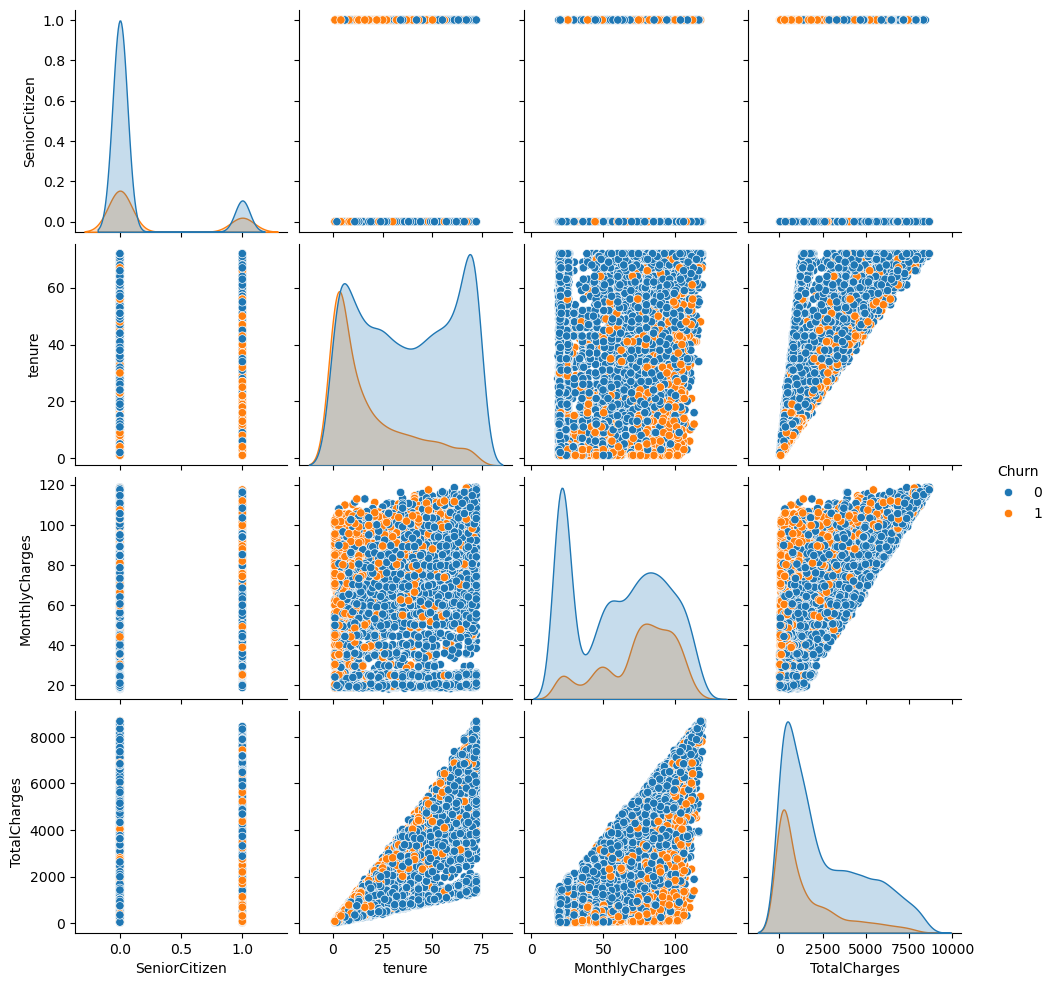

In [60]:
# Lets explore Feature - Feature, 

sns.pairplot(data, hue='Churn')

In [61]:
# Data Modelling

In [62]:
data.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [63]:
df = data.copy()

In [64]:
for col in dis_object_columns:
    print(f'{col}')
    print(data[col].value_counts(normalize=True))
    print('=====================================')

SeniorCitizen
SeniorCitizen
0    0.8376
1    0.1624
Name: proportion, dtype: float64
gender
gender
Male      0.504693
Female    0.495307
Name: proportion, dtype: float64
Partner
Partner
No     0.517491
Yes    0.482509
Name: proportion, dtype: float64
Dependents
Dependents
No     0.701507
Yes    0.298493
Name: proportion, dtype: float64
PhoneService
PhoneService
Yes    0.903299
No     0.096701
Name: proportion, dtype: float64
MultipleLines
MultipleLines
No                  0.481371
Yes                 0.421928
No phone service    0.096701
Name: proportion, dtype: float64
InternetService
InternetService
Fiber optic    0.440273
DSL            0.343572
No             0.216155
Name: proportion, dtype: float64
OnlineSecurity
OnlineSecurity
No                     0.497298
Yes                    0.286547
No internet service    0.216155
Name: proportion, dtype: float64
OnlineBackup
OnlineBackup
No                     0.438993
Yes                    0.344852
No internet service    0.216155
Name:

In [65]:
df['gender'] = df['gender'].map({
    'Male': 1,
    'Female': 0
})

In [66]:
df['Partner'] = df['Partner'].map({
    'Yes': 1,
    'No': 0
})

In [67]:
df['Dependents'] = df['Dependents'].map({
    'Yes': 1,
    'No': 0
})

In [68]:
df['PhoneService'] = df['PhoneService'].map({
    'Yes': 1,
    'No': 0
})

In [69]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,0,0,1,0,1,0,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,1,0,0,0,34,1,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,1,0,0,0,2,1,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,1,0,0,0,45,0,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,0,0,0,0,2,1,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [70]:
mul_lines = (pd.get_dummies(df['MultipleLines'])
 .astype(int)
 .drop(columns=['No phone service'])
 .rename(columns={
     'Yes': 'MultipleLines_Yes',
     'No': 'MultipleLines_No'
 }))

In [71]:
df = df.drop(columns=['MultipleLines'])

In [72]:
df = pd.concat([df, mul_lines], axis=1)

In [73]:
int_service = (pd.get_dummies(df['InternetService'])
 .astype(int)
 .drop(columns=['No']))

In [74]:
int_service[(int_service['DSL']==0) & (int_service['Fiber optic']==0)]

,DSL,Fiber optic
11,0,0
16,0,0
21,0,0
22,0,0
33,0,0
...,...,...
7006,0,0
7008,0,0
7009,0,0
7019,0,0


In [75]:
df = pd.concat([df, int_service], axis=1)

In [76]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,InternetService,OnlineSecurity,OnlineBackup,...,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,MultipleLines_No,MultipleLines_Yes,DSL,Fiber optic
0,7590-VHVEG,0,0,1,0,1,0,DSL,No,Yes,...,Month-to-month,Yes,Electronic check,29.85,29.85,0,0,0,1,0
1,5575-GNVDE,1,0,0,0,34,1,DSL,Yes,No,...,One year,No,Mailed check,56.95,1889.50,0,1,0,1,0
2,3668-QPYBK,1,0,0,0,2,1,DSL,Yes,Yes,...,Month-to-month,Yes,Mailed check,53.85,108.15,1,1,0,1,0
3,7795-CFOCW,1,0,0,0,45,0,DSL,Yes,No,...,One year,No,Bank transfer (automatic),42.30,1840.75,0,0,0,1,0
4,9237-HQITU,0,0,0,0,2,1,Fiber optic,No,No,...,Month-to-month,Yes,Electronic check,70.70,151.65,1,1,0,0,1


In [77]:
df = df.drop(columns=['InternetService'])

In [78]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,OnlineSecurity,OnlineBackup,DeviceProtection,...,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,MultipleLines_No,MultipleLines_Yes,DSL,Fiber optic
0,7590-VHVEG,0,0,1,0,1,0,No,Yes,No,...,Month-to-month,Yes,Electronic check,29.85,29.85,0,0,0,1,0
1,5575-GNVDE,1,0,0,0,34,1,Yes,No,Yes,...,One year,No,Mailed check,56.95,1889.50,0,1,0,1,0
2,3668-QPYBK,1,0,0,0,2,1,Yes,Yes,No,...,Month-to-month,Yes,Mailed check,53.85,108.15,1,1,0,1,0
3,7795-CFOCW,1,0,0,0,45,0,Yes,No,Yes,...,One year,No,Bank transfer (automatic),42.30,1840.75,0,0,0,1,0
4,9237-HQITU,0,0,0,0,2,1,No,No,No,...,Month-to-month,Yes,Electronic check,70.70,151.65,1,1,0,0,1


In [79]:
np.unique(df['OnlineBackup'])

array(['No', 'No internet service', 'Yes'], dtype=object)

In [80]:
for col in ['OnlineSecurity', 'OnlineBackup', 'TechSupport', 'DeviceProtection', 'StreamingTV', 'StreamingMovies']:
    dummies = (pd.get_dummies(df[col])
     .astype(int)
     .drop(columns=['No internet service'])
     .rename(columns={
         'Yes': f'{col}_Yes',
         'No': f'{col}_No'
     }))
    df = (pd.concat([df, dummies], axis=1)).drop(columns=[col])

In [81]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,Contract,PaperlessBilling,PaymentMethod,...,OnlineBackup_No,OnlineBackup_Yes,TechSupport_No,TechSupport_Yes,DeviceProtection_No,DeviceProtection_Yes,StreamingTV_No,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_Yes
0,7590-VHVEG,0,0,1,0,1,0,Month-to-month,Yes,Electronic check,...,0,1,1,0,1,0,1,0,1,0
1,5575-GNVDE,1,0,0,0,34,1,One year,No,Mailed check,...,1,0,1,0,0,1,1,0,1,0
2,3668-QPYBK,1,0,0,0,2,1,Month-to-month,Yes,Mailed check,...,0,1,1,0,1,0,1,0,1,0
3,7795-CFOCW,1,0,0,0,45,0,One year,No,Bank transfer (automatic),...,1,0,0,1,0,1,1,0,1,0
4,9237-HQITU,0,0,0,0,2,1,Month-to-month,Yes,Electronic check,...,1,0,1,0,1,0,1,0,1,0


In [82]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn',
       'MultipleLines_No', 'MultipleLines_Yes', 'DSL', 'Fiber optic',
       'OnlineSecurity_No', 'OnlineSecurity_Yes', 'OnlineBackup_No',
       'OnlineBackup_Yes', 'TechSupport_No', 'TechSupport_Yes',
       'DeviceProtection_No', 'DeviceProtection_Yes', 'StreamingTV_No',
       'StreamingTV_Yes', 'StreamingMovies_No', 'StreamingMovies_Yes'],
      dtype='object')

In [83]:
df = (
    pd.concat([df, (pd.get_dummies(data['Contract'], drop_first=True).astype('int')).rename(
    columns={
        'One year': 'Contract One year',
        'Two year': 'Contract Two year'
    }
)], axis=1).drop(columns=['Contract'])
)

In [84]:
df['PaperlessBilling'] = df['PaperlessBilling'].map({
    'Yes': 1,
    'No': 0
})

In [85]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,PaymentMethod,MonthlyCharges,...,TechSupport_No,TechSupport_Yes,DeviceProtection_No,DeviceProtection_Yes,StreamingTV_No,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_Yes,Contract One year,Contract Two year
0,7590-VHVEG,0,0,1,0,1,0,1,Electronic check,29.85,...,1,0,1,0,1,0,1,0,0,0
1,5575-GNVDE,1,0,0,0,34,1,0,Mailed check,56.95,...,1,0,0,1,1,0,1,0,1,0
2,3668-QPYBK,1,0,0,0,2,1,1,Mailed check,53.85,...,1,0,1,0,1,0,1,0,0,0
3,7795-CFOCW,1,0,0,0,45,0,0,Bank transfer (automatic),42.30,...,0,1,0,1,1,0,1,0,1,0
4,9237-HQITU,0,0,0,0,2,1,1,Electronic check,70.70,...,1,0,1,0,1,0,1,0,0,0


In [86]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn', 'MultipleLines_No',
       'MultipleLines_Yes', 'DSL', 'Fiber optic', 'OnlineSecurity_No',
       'OnlineSecurity_Yes', 'OnlineBackup_No', 'OnlineBackup_Yes',
       'TechSupport_No', 'TechSupport_Yes', 'DeviceProtection_No',
       'DeviceProtection_Yes', 'StreamingTV_No', 'StreamingTV_Yes',
       'StreamingMovies_No', 'StreamingMovies_Yes', 'Contract One year',
       'Contract Two year'],
      dtype='object')

In [87]:
np.unique(df['PaymentMethod'])

array(['Bank transfer (automatic)', 'Credit card (automatic)',
       'Electronic check', 'Mailed check'], dtype=object)

In [88]:
x = (pd.get_dummies(df['PaymentMethod'], drop_first=True).astype('int'))
df = pd.concat([df, x], axis=1).drop(columns='PaymentMethod')

In [89]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,...,DeviceProtection_Yes,StreamingTV_No,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_Yes,Contract One year,Contract Two year,Credit card (automatic),Electronic check,Mailed check
0,7590-VHVEG,0,0,1,0,1,0,1,29.85,29.85,...,0,1,0,1,0,0,0,0,1,0
1,5575-GNVDE,1,0,0,0,34,1,0,56.95,1889.50,...,1,1,0,1,0,1,0,0,0,1
2,3668-QPYBK,1,0,0,0,2,1,1,53.85,108.15,...,0,1,0,1,0,0,0,0,0,1
3,7795-CFOCW,1,0,0,0,45,0,0,42.30,1840.75,...,1,1,0,1,0,1,0,0,0,0
4,9237-HQITU,0,0,0,0,2,1,1,70.70,151.65,...,0,1,0,1,0,0,0,0,1,0


In [90]:
df.dtypes

customerID                  object
gender                       int64
SeniorCitizen                int64
Partner                      int64
Dependents                   int64
tenure                       int64
PhoneService                 int64
PaperlessBilling             int64
MonthlyCharges             float64
TotalCharges               float64
Churn                        int64
MultipleLines_No             int64
MultipleLines_Yes            int64
DSL                          int64
Fiber optic                  int64
OnlineSecurity_No            int64
OnlineSecurity_Yes           int64
OnlineBackup_No              int64
OnlineBackup_Yes             int64
TechSupport_No               int64
TechSupport_Yes              int64
DeviceProtection_No          int64
DeviceProtection_Yes         int64
StreamingTV_No               int64
StreamingTV_Yes              int64
StreamingMovies_No           int64
StreamingMovies_Yes          int64
Contract One year            int64
Contract Two year   

In [91]:
# Now lets add to more features, customer lifetime value proxy and spend consistency

df['lifetime_value_proxy'] = (df['tenure']) * (df['MonthlyCharges'])  # This is a rough estimate of how much total revenue a customer has generated for the company.
df['spend_consistency'] = df['TotalCharges'] / (df['tenure'] + 1) # This answers the question: is what a customer pays now consistent with what they've paid historically?


In [92]:
X = (df.iloc[:,1:]).drop(columns=['Churn'])
y = df['Churn']

In [93]:
# MOdel Fitting

# First we will split the data into train test split


X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, stratify=y
)




In [94]:
X_train

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No,...,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_Yes,Contract One year,Contract Two year,Credit card (automatic),Electronic check,Mailed check,lifetime_value_proxy,spend_consistency
6631,1,0,1,1,28,0,0,50.80,1386.80,0,...,1,1,0,1,0,0,0,1,1422.40,47.820690
5172,0,0,0,0,68,0,0,64.35,4539.60,0,...,1,0,1,0,1,1,0,0,4375.80,65.791304
4737,0,0,1,0,34,1,1,100.45,3414.65,0,...,1,0,1,0,0,0,1,0,3415.30,97.561429
2388,0,0,1,1,33,1,1,103.70,3467.00,0,...,1,0,1,1,0,0,0,1,3422.10,101.970588
2608,0,0,0,0,1,1,1,80.20,80.20,0,...,0,1,0,0,0,0,0,1,80.20,40.100000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4368,1,0,0,0,66,1,1,114.30,7383.70,0,...,1,0,1,1,0,0,0,0,7543.80,110.204478
4352,0,0,0,0,23,1,1,98.70,2249.10,0,...,1,0,1,0,0,1,0,0,2270.10,93.712500
5155,1,0,1,1,19,0,1,34.95,610.20,0,...,0,1,0,0,0,0,0,1,664.05,30.510000
5994,0,0,1,0,71,1,0,93.20,6506.15,0,...,1,0,1,0,1,1,0,0,6617.20,90.363194


In [95]:
X_test

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No,...,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_Yes,Contract One year,Contract Two year,Credit card (automatic),Electronic check,Mailed check,lifetime_value_proxy,spend_consistency
3741,0,0,1,1,4,1,1,58.50,224.85,0,...,0,1,0,0,0,0,0,1,234.00,44.970000
2355,1,0,1,1,62,1,0,20.05,1263.90,1,...,0,0,0,0,1,1,0,0,1243.10,20.061905
4887,0,1,1,0,44,1,1,85.15,3670.50,1,...,0,1,0,0,0,0,1,0,3746.60,81.566667
5878,1,0,0,1,17,1,1,50.30,846.80,1,...,0,1,0,0,0,0,0,1,855.10,47.044444
3060,1,0,0,0,1,1,1,45.80,45.80,1,...,0,1,0,0,0,0,0,1,45.80,22.900000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1546,1,0,0,0,22,1,0,25.25,566.50,0,...,0,0,0,0,1,0,0,1,555.50,24.630435
3171,0,0,1,0,51,1,0,25.50,1281.25,0,...,0,0,0,0,1,0,0,1,1300.50,24.639423
4567,1,0,0,0,4,1,0,25.25,101.90,0,...,0,0,0,0,0,0,0,1,101.00,20.380000
2396,1,1,0,1,11,1,1,54.55,601.25,1,...,0,1,0,0,0,0,1,0,600.05,50.104167


In [96]:
y_train.value_counts(normalize=True)

Churn
0    0.734222
1    0.265778
Name: proportion, dtype: float64

In [97]:
y_test.value_counts(normalize=True)

Churn
0    0.734186
1    0.265814
Name: proportion, dtype: float64

In [98]:
# Decision Tree

dt = DecisionTreeClassifier(random_state=42)
dt = dt.fit(X_train, y_train)


In [99]:
y_pred = dt.predict(X_test)

In [100]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.7313432835820896

Confusion Matrix:
 [[845 188]
 [190 184]]

Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.82      0.82      1033
           1       0.49      0.49      0.49       374

    accuracy                           0.73      1407
   macro avg       0.66      0.65      0.66      1407
weighted avg       0.73      0.73      0.73      1407



In [101]:


feature_importance = pd.Series(dt.feature_importances_, index=X.columns)
feature_importance = feature_importance.sort_values(ascending=False)

<Axes: >

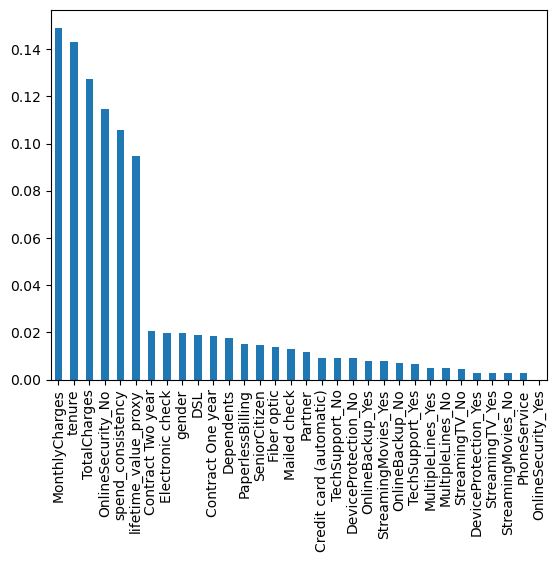

In [102]:
feature_importance.plot.bar()

In [103]:
# From here spend_consisitency, tenure, MonthlyCharges, lifetime_value_proxy, Total CHarges play a huge role

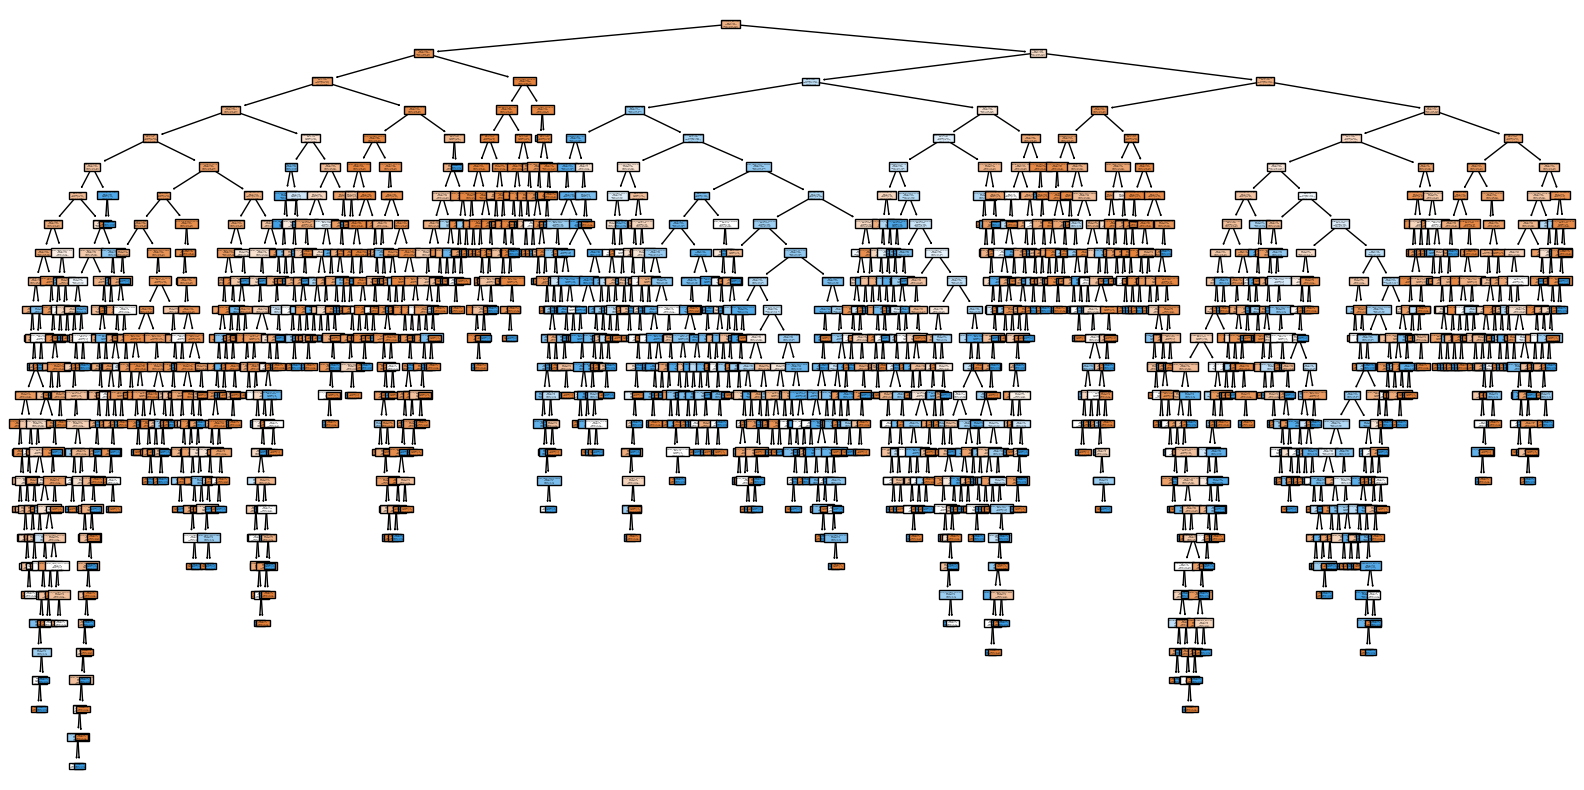

In [104]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20,10))
plot_tree(dt, feature_names=X.columns, class_names=['No Churn','Churn'], filled=True)
plt.show()

In [105]:
score(y_train, dt.predict(X_train))

Accuracy: 0.9978666666666667
Precision: 0.9926421404682274
Recall: 0.9993265993265993
F-1 Score: 0.9959731543624161
ROC, AUC Score: 0.9983347972478408


In [106]:
score(y_test, dt.predict(X_test))

Accuracy: 0.7313432835820896
Precision: 0.4919786096256685
Recall: 0.4946236559139785
F-1 Score: 0.4932975871313673
ROC, AUC Score: 0.6555243883434627


In [107]:
# Our model has overfitted thus we will need to hyperparam tune

In [108]:
# Lets use GridSearchCv for hyperparameter tuning


dt = DecisionTreeClassifier(random_state=42)

param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10, 20, 30, 45, 50, 55, 60, 75, 100],
    'min_samples_leaf': [1, 2, 5, 10, 30]
}

grid = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    cv=5,                    
    scoring='f1',           
    n_jobs=-1,               
    verbose=1
)

grid.fit(X_train, y_train)

Fitting 5 folds for each of 550 candidates, totalling 2750 fits


,estimator,DecisionTreeC...ndom_state=42)
,param_grid,"{'criterion': ['gini', 'entropy'], 'max_depth': [3, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'entropy'


In [109]:
dt = DecisionTreeClassifier(
    random_state=42,
    max_depth=7,
    criterion='entropy',
    splitter='best',
    min_samples_split=30,
    min_samples_leaf=2
)

In [110]:
dt.fit(X_train, y_train)

,criterion,'entropy'
,splitter,'best'
,max_depth,7
,min_samples_split,30
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [111]:
score(y_train, dt.predict(X_train))

Accuracy: 0.8081777777777778
Precision: 0.6287625418060201
Recall: 0.6420765027322405
F-1 Score: 0.6353497803311929
ROC, AUC Score: 0.7543475520150028


In [112]:
score(y_test, dt.predict(X_test))

Accuracy: 0.7825159914712153
Precision: 0.5721925133689839
Recall: 0.5944444444444444
F-1 Score: 0.5831062670299727
ROC, AUC Score: 0.720813435211716


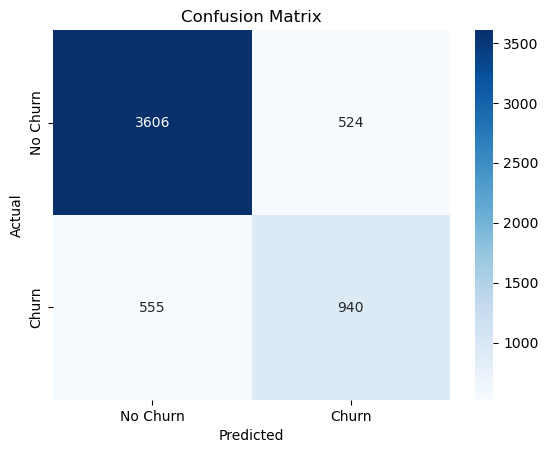

In [113]:
plot_confusion_matrix(dt, X_train, y_train)

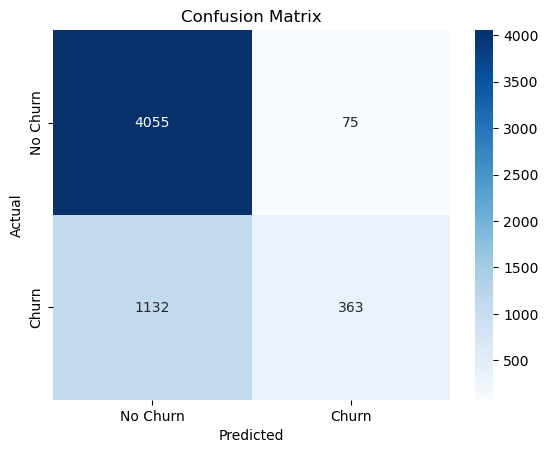

In [114]:
# We want precision, but dominantly recall to be good
# Increasing threshold has not helped us
plot_confusion_matrix(dt, X_train, y_train, threshold=0.70)

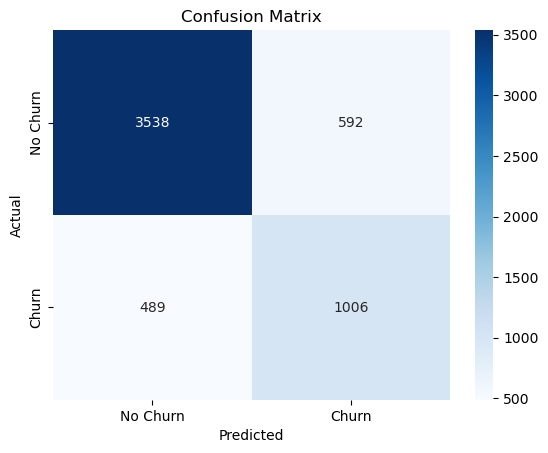

In [115]:
plot_confusion_matrix(dt, X_train, y_train, threshold=0.40)

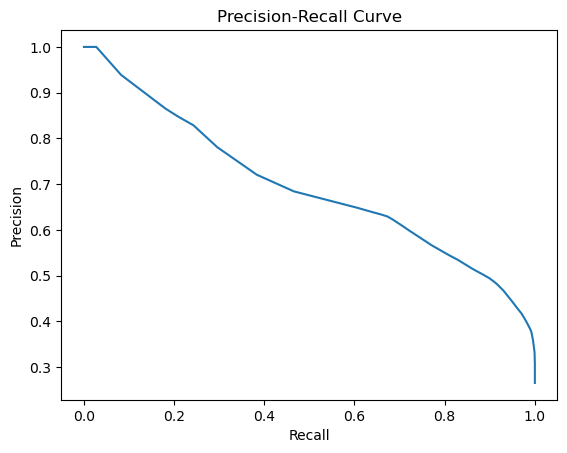

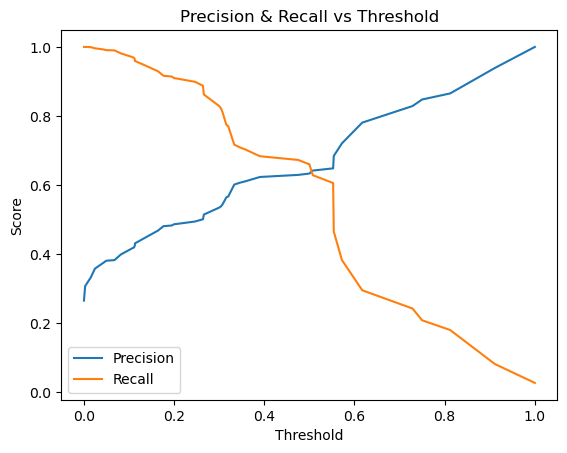

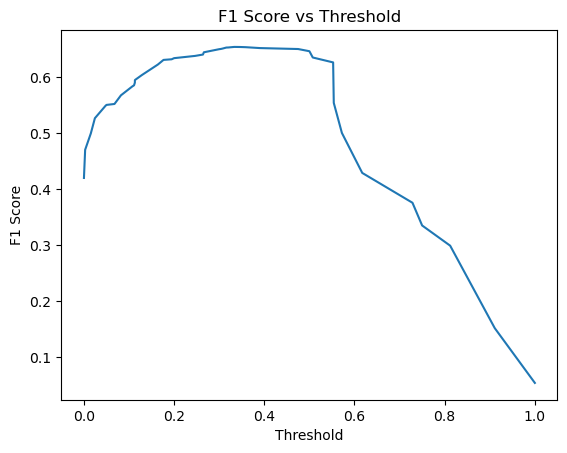

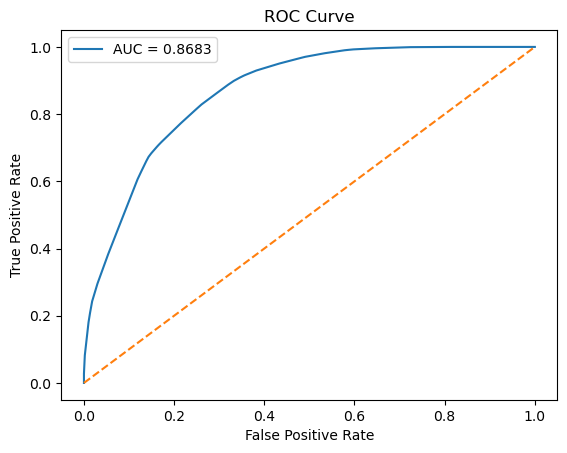

In [116]:
plot_classification_curves(dt, X_train, y_train)

In [117]:
score(dt.predict_proba(X_train)[:, 1] >= 0.30, y_train)

Accuracy: 0.7630222222222223
Precision: 0.5349740932642487
Recall: 0.82876254180602
F-1 Score: 0.6502230385725531
ROC, AUC Score: 0.7839938617020414


In [118]:
score(dt.predict_proba(X_test)[:, 1] >= 0.30, y_test)

Accuracy: 0.7334754797441365
Precision: 0.4991304347826087
Recall: 0.767379679144385
F-1 Score: 0.6048472075869337
ROC, AUC Score: 0.7442900331830347


In [119]:
# Okay so for decison tree, our best yet model would be, with decision threshold 0.30

best_dt = dt

In [120]:

feature_importance = pd.Series(best_dt.feature_importances_, index=X.columns)
feature_importance = feature_importance.sort_values(ascending=False)

<Axes: >

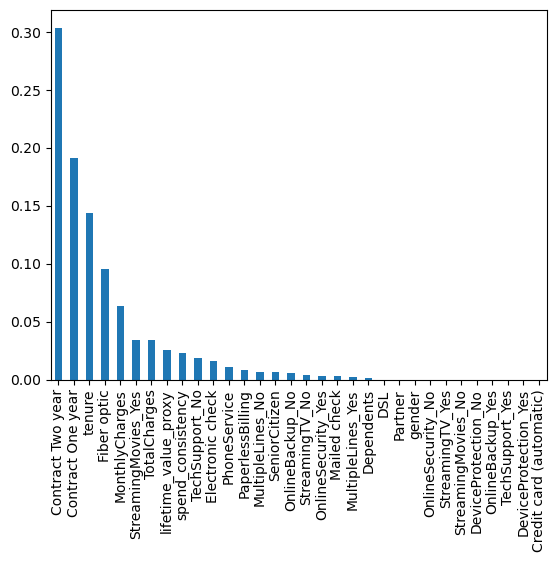

In [121]:
feature_importance.plot.bar()

In [122]:
# From here we can see contract of one year and two year have a great influence
# ALso tenure, Fibre Optic and Total Charges

In [123]:
# Random Forest


rf = RandomForestClassifier(
    n_estimators=200,        # number of trees
    max_depth=None,          # let trees grow (can tune later)
    class_weight='balanced', # important for churn
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [124]:
score(rf.predict(X_train), y_train)

Accuracy: 0.9978666666666667
Precision: 0.9940039973351099
Recall: 0.9979933110367893
F-1 Score: 0.9959946595460614
ROC, AUC Score: 0.9979070671406707


In [125]:
score(rf.predict(X_test), y_test)

Accuracy: 0.8116560056858564
Precision: 0.6967509025270758
Recall: 0.516042780748663
F-1 Score: 0.5929339477726574
ROC, AUC Score: 0.7173631135108273


In [126]:
rf = RandomForestClassifier(
    n_estimators=200,        # number of trees
    max_depth=7,          # let trees grow (can tune later)
    class_weight={
    0:1,1:3
    }, 
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

In [127]:
rf.fit(X_train, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,7
,min_samples_split,2
,min_samples_leaf,10
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [128]:
score(rf.predict(X_train), y_train)

Accuracy: 0.7847111111111111
Precision: 0.5630550621669627
Recall: 0.8481605351170568
F-1 Score: 0.6768081131571925
ROC, AUC Score: 0.8049519382607077


In [129]:
score(rf.predict(X_test), y_test)

Accuracy: 0.757640369580668
Precision: 0.5289982425307557
Recall: 0.8048128342245989
F-1 Score: 0.6383881230116649
ROC, AUC Score: 0.7726871528334998


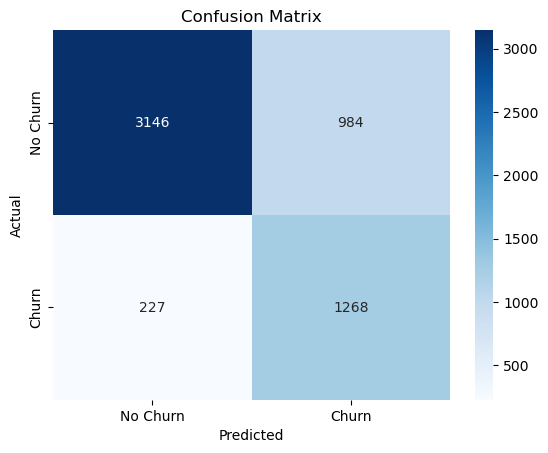

In [130]:
plot_confusion_matrix(rf, X_train, y_train)

In [131]:
# Our recall is good but beacause of which our model id predicting most of thhem as churn thus FP increases
# Lets drop the weight for 1 by 1 unit

In [132]:
rf_2 = RandomForestClassifier(
    n_estimators=200,        # number of trees
    max_depth=7,          # let trees grow (can tune later)
    class_weight={
    0:1,1:2
    }, 
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_2.fit(X_train, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,7
,min_samples_split,2
,min_samples_leaf,10
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [133]:
score(rf_2.predict(X_train), y_train)

Accuracy: 0.8065777777777777
Precision: 0.6141334828939988
Recall: 0.7324414715719063
F-1 Score: 0.6680902989627822
ROC, AUC Score: 0.7829277575777207


In [134]:
score(rf_2.predict(X_test), y_test)

Accuracy: 0.7910447761194029
Precision: 0.5930232558139535
Recall: 0.6818181818181818
F-1 Score: 0.6343283582089553
ROC, AUC Score: 0.7562043474434568


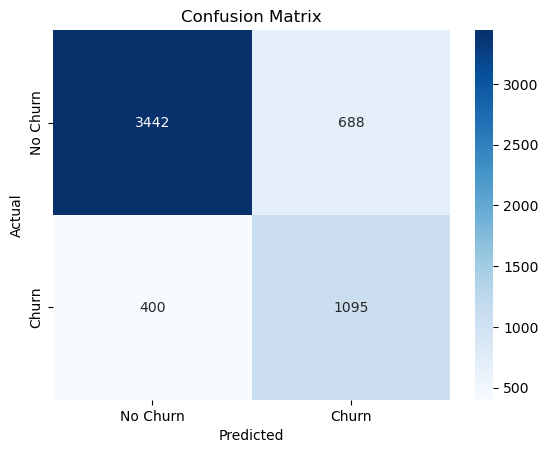

In [135]:
plot_confusion_matrix(rf_2, X_train, y_train)

In [136]:
# In this our precsion has improved a bit

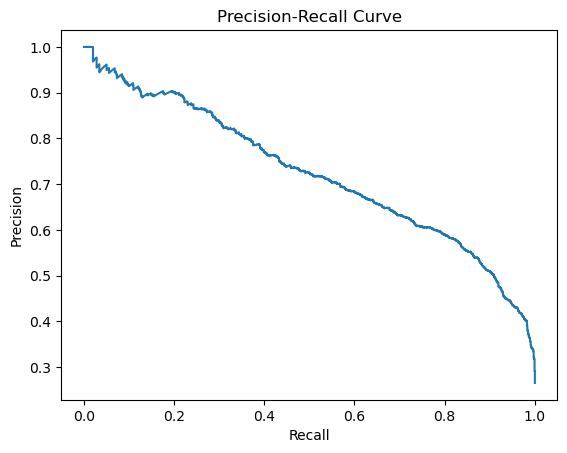

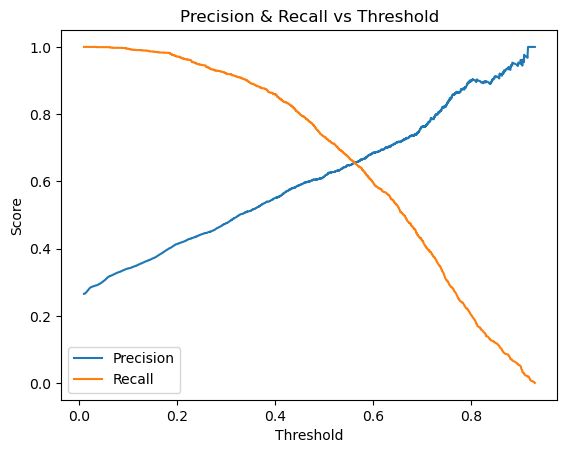

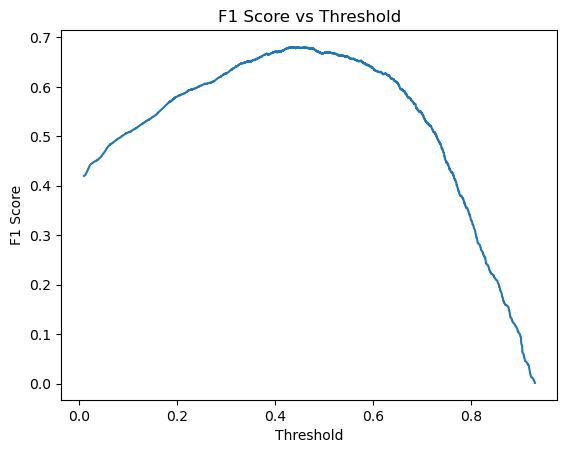

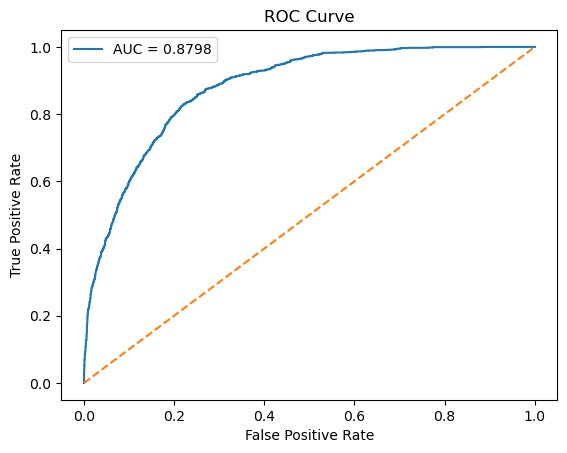

In [137]:
# LEt see whether we can fine tune the thresholds
plot_classification_curves(rf_2, X_train, y_train)

In [138]:
# For now we will take rf_2 as the best model for Random Forest yet
best_rf = rf_2

In [139]:
rf_2.feature_importances_

array([0.00377244, 0.00601003, 0.00408807, 0.00530205, 0.13831968,
       0.00229362, 0.01359803, 0.05998589, 0.08614003, 0.00419608,
       0.00444411, 0.02182412, 0.06471137, 0.09242721, 0.01114829,
       0.02644839, 0.00444344, 0.08886457, 0.01136514, 0.01778121,
       0.00322157, 0.00470988, 0.0038574 , 0.0056513 , 0.0046674 ,
       0.03135604, 0.08457456, 0.00286782, 0.05488159, 0.00362242,
       0.08299771, 0.05042856])

In [140]:
feature_importance = pd.Series(best_rf.feature_importances_, index=X.columns)
feature_importance = feature_importance.sort_values(ascending=False)

<Axes: >

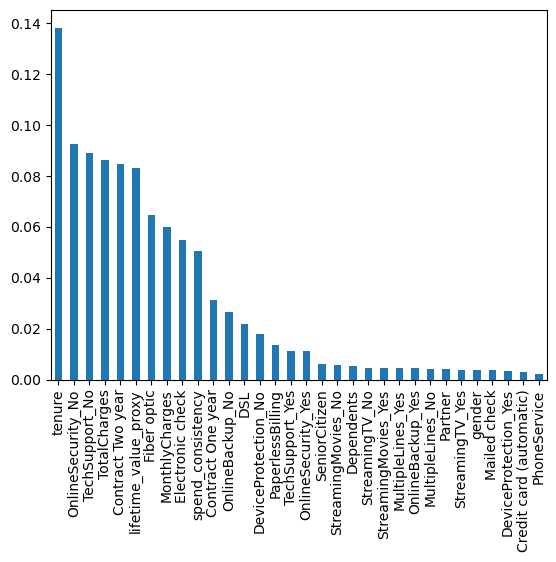

In [141]:
feature_importance.plot.bar()

In [142]:
# According to this charts
# tenure, Online_Security_No, Contract of Two year, Fibre Optic, Monthly Charges, lifetime_value_proxy
# have a great influence.

In [143]:
# Logistic Rgeression

In [144]:
# By default Ridge Regularization, shrinks weights
logreg = LogisticRegression(max_iter=100000, random_state=42)
logreg.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100000
,multi_class,'deprecated'


In [145]:
score(logreg.predict(X_train), y_train)

Accuracy: 0.8088888888888889
Precision: 0.6807228915662651
Recall: 0.5290969899665552
F-1 Score: 0.5954083552879187
ROC, AUC Score: 0.7196332407459894


In [146]:
score(logreg.predict(X_test), y_test)

Accuracy: 0.8123667377398721
Precision: 0.6964285714285714
Recall: 0.5213903743315508
F-1 Score: 0.5963302752293578
ROC, AUC Score: 0.7195528831967531


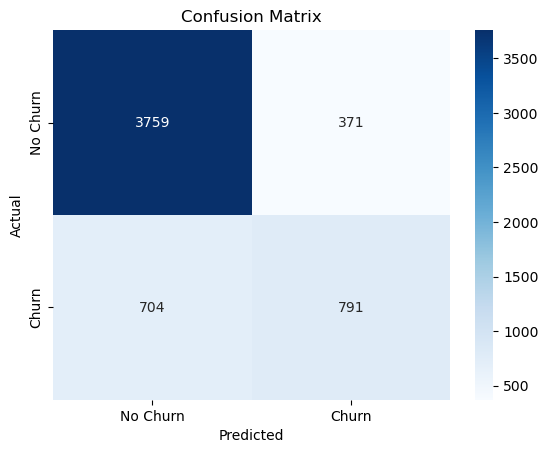

In [147]:
plot_confusion_matrix(logreg, X_train, y_train)

In [148]:
# COmpared to best_rf, this model has good precision

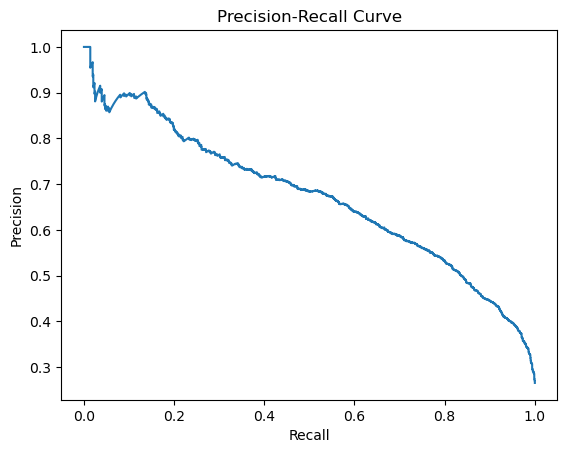

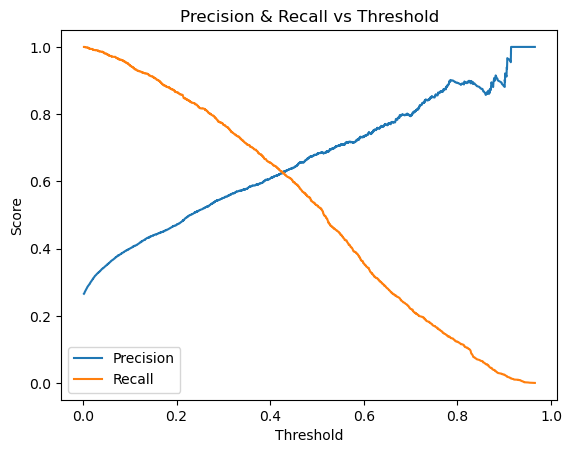

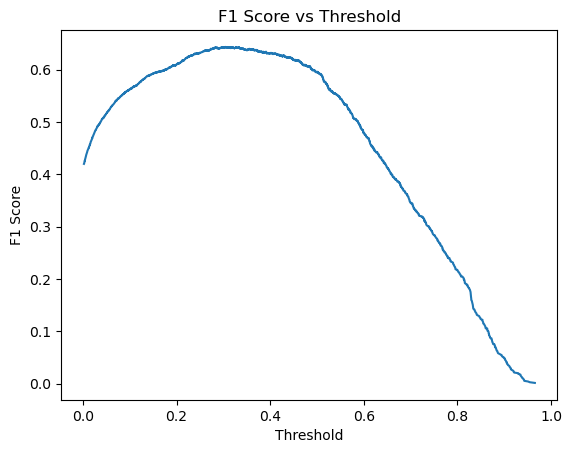

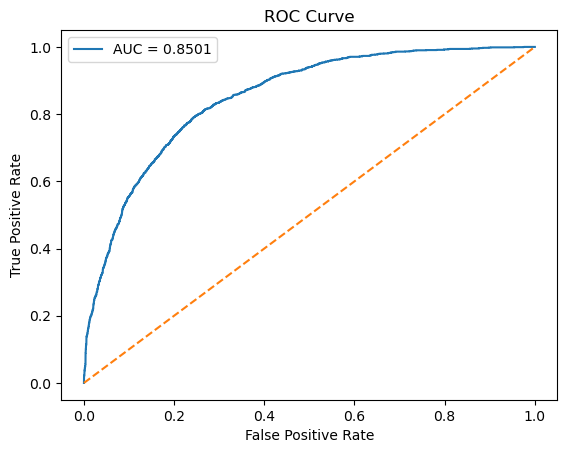

In [149]:
plot_classification_curves(logreg, X_train, y_train)

In [150]:
(pd.DataFrame(np.reshape(logreg.coef_, (-1, 1)), index=X_train.columns, columns=['Ceoff'])).sort_values(by='Ceoff', ascending=False)

,Ceoff
Fiber optic,0.516468
PaperlessBilling,0.364904
OnlineSecurity_No,0.283881
StreamingMovies_Yes,0.273883
SeniorCitizen,0.273575
TechSupport_No,0.271582
Electronic check,0.262730
StreamingTV_Yes,0.247261
OnlineBackup_No,0.211897
DeviceProtection_Yes,0.174939


In [151]:
## Fiber optic	0.73
# PaperlessBilling	0.39
# Streaming TV_yes 0.37
# OnlineSecurity_No	0.33
# TechSupport_No	0.32
# SeniorCitizen	0.20
# These features majorly play a huge role in increasing the predicted prob



In [152]:
# Lets scale the data and see how the model performs

std = StandardScaler()
X_train_std = std.fit_transform(X_train)
X_test_std = std.transform(X_test)



In [153]:
logreg_2 = LogisticRegression(max_iter=100000, random_state=42)
logreg_2.fit(X_train_std, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100000
,multi_class,'deprecated'


In [154]:
score(logreg_2.predict(X_train_std), y_train)

Accuracy: 0.8085333333333333
Precision: 0.6783276450511946
Recall: 0.5317725752508361
F-1 Score: 0.5961754780652418
ROC, AUC Score: 0.7202446411363138


In [155]:
score(logreg_2.predict(X_test_std), y_test)

Accuracy: 0.8116560056858564
Precision: 0.6898954703832753
Recall: 0.5294117647058824
F-1 Score: 0.5990922844175491
ROC, AUC Score: 0.7216274699618472


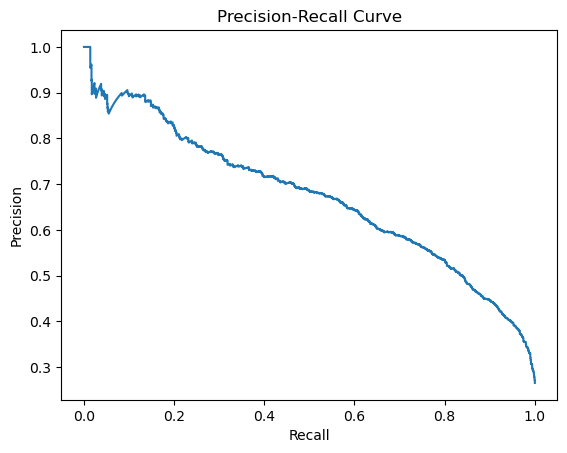

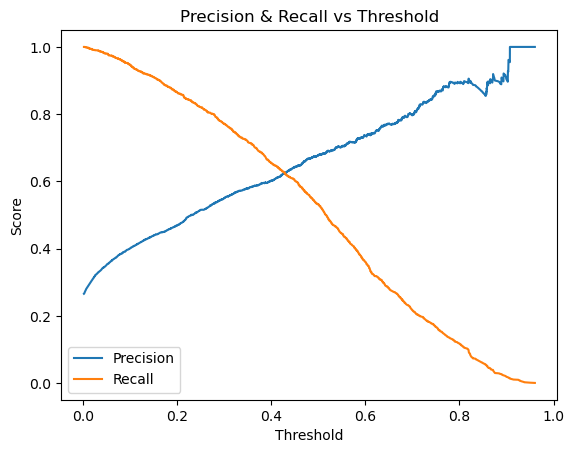

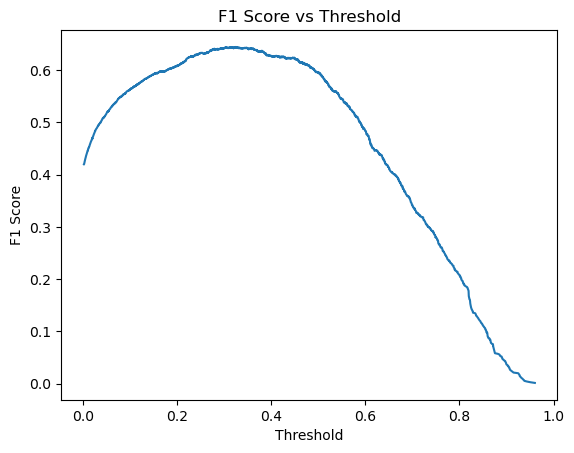

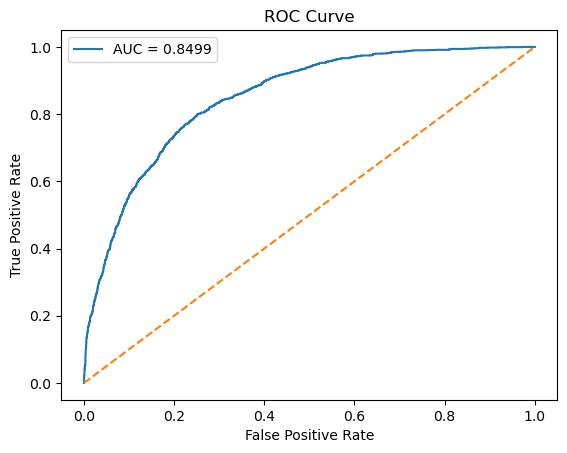

In [156]:
plot_classification_curves(logreg_2, X_train_std, y_train)

In [157]:
# Didnt made any drastic Difference

# Letssee gridsearch cv

from sklearn.model_selection import GridSearchCV

param_grid = {
    'penalty': ['l1', 'l2'],
    'C': [0.01, 0.1, 1, 10],
    'solver': ['liblinear']
}

grid = GridSearchCV(
    LogisticRegression(max_iter=100000, random_state=42),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid.fit(X_train_std, y_train)

print("Best Params:", grid.best_params_)
print("Best Score:", grid.best_score_)


Best Params: {'C': 0.01, 'penalty': 'l2', 'solver': 'liblinear'}
Best Score: 0.5949305486061921


In [158]:
# No luck over here

In [159]:
logreg_best = logreg

In [160]:
# Now lets see knn

In [161]:
# Create model
knn = KNeighborsClassifier(n_neighbors=5)

# Train
knn.fit(X_train_std, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [162]:
score(knn.predict(X_train_std), y_train)

Accuracy: 0.8355555555555556
Precision: 0.7142857142857143
Recall: 0.6354515050167224
F-1 Score: 0.672566371681416
ROC, AUC Score: 0.7717209098933492


In [163]:
score(knn.predict(X_test_std), y_test)

Accuracy: 0.7569296375266524
Precision: 0.549079754601227
Recall: 0.4786096256684492
F-1 Score: 0.5114285714285715
ROC, AUC Score: 0.6681528283230919


In [164]:
# For train it performed well, but for test no so good

In [165]:
# Lets see for gridsearch cv
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best Params:", grid.best_params_)
print("Best Score:", grid.best_score_)

Best Params: {'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'uniform'}
Best Score: 0.5053402309800517


In [166]:
# Create model
knn_2 = KNeighborsClassifier(**grid.best_params_)

# Train
knn_2.fit(X_train_std, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'manhattan'
,metric_params,None
,n_jobs,None


In [167]:
score(knn_2.predict(X_train_std), y_train)

Accuracy: 0.8378666666666666
Precision: 0.7170513775130305
Recall: 0.6441471571906354
F-1 Score: 0.678646934460888
ROC, AUC Score: 0.7760687359803056


In [168]:
score(knn_2.predict(X_test_std), y_test)

Accuracy: 0.7590618336886994
Precision: 0.5531914893617021
Recall: 0.48663101604278075
F-1 Score: 0.5177809388335705
ROC, AUC Score: 0.6721635235102578


In [169]:
# The model overfitted

In [170]:
# So for now randome forest was our best model

In [171]:
best_rf

,n_estimators,200
,criterion,'gini'
,max_depth,7
,min_samples_split,2
,min_samples_leaf,10
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [172]:
# Now lets tackle class imbalance

In [173]:
y_train.value_counts(normalize=True)

Churn
0    0.734222
1    0.265778
Name: proportion, dtype: float64

In [174]:
# Let perform undersampling

import imblearn.under_sampling as US

minority_pct = 0.40

RUS = US.RandomUnderSampler(sampling_strategy=(minority_pct)/(1-minority_pct), random_state=42)

In [175]:
X_train_rs, y_train_rs = RUS.fit_resample(X_train, y_train)

In [176]:
y_train_rs.value_counts(normalize=True)

Churn
0    0.599946
1    0.400054
Name: proportion, dtype: float64

In [177]:
# Now lets fit our models again

In [178]:
rf_bal = RandomForestClassifier(
    n_estimators=200,        # number of trees
    max_depth=7,          # let trees grow (can tune later)
    class_weight={
    0:1,1:2
    }, 
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

rf_bal.fit(X_train_rs, y_train_rs)

,n_estimators,200
,criterion,'gini'
,max_depth,7
,min_samples_split,2
,min_samples_leaf,10
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [179]:
score(rf_bal.predict(X_train_rs), y_train_rs)

Accuracy: 0.7795022745517795
Precision: 0.6712608473711077
Recall: 0.8795986622073578
F-1 Score: 0.7614360162130863
ROC, AUC Score: 0.7961775648235718


In [180]:
score(rf_bal.predict(X_test), y_test)

Accuracy: 0.7313432835820896
Precision: 0.4969512195121951
Recall: 0.8716577540106952
F-1 Score: 0.6330097087378641
ROC, AUC Score: 0.7760999321844377


In [181]:

feature_importance = pd.Series(rf_bal.feature_importances_, index=X.columns)
feature_importance = feature_importance.sort_values(ascending=False)

<Axes: >

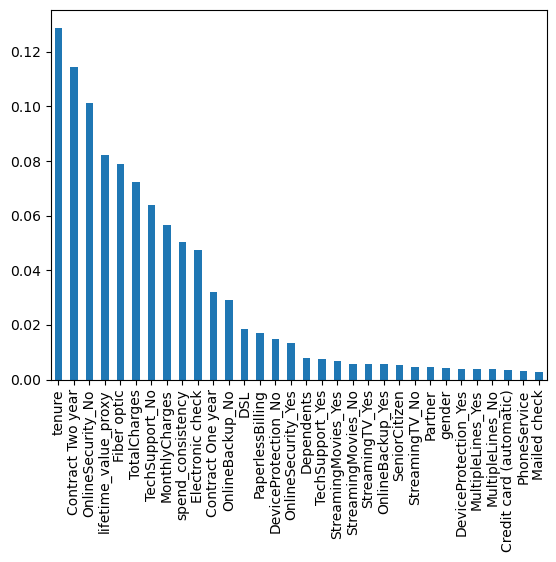

In [182]:
feature_importance.plot.bar()

In [183]:
# From here we can see that tenure, Contract Two year, Online Security No, Techsupport No, engineerd features and Fibre Optic
# heavlily influence

In [184]:
# GBM model
gbm = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train
gbm.fit(X_train_std, y_train)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [185]:
score(gbm.predict(X_train_std), y_train)

Accuracy: 0.8300444444444445
Precision: 0.7325280414150129
Recall: 0.5678929765886288
F-1 Score: 0.6397889977392615
ROC, AUC Score: 0.7464162219504887


In [186]:
score(gbm.predict(X_test_std), y_test)

Accuracy: 0.8081023454157783
Precision: 0.6818181818181818
Recall: 0.5213903743315508
F-1 Score: 0.5909090909090909
ROC, AUC Score: 0.7166487205636457


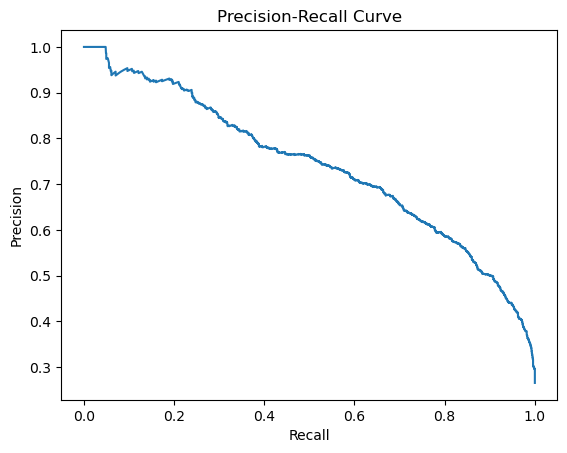

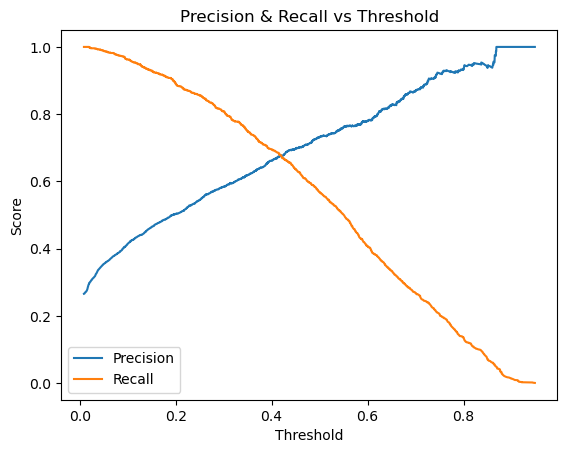

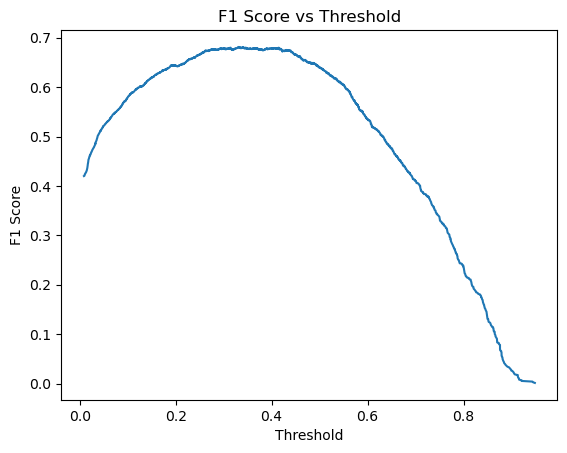

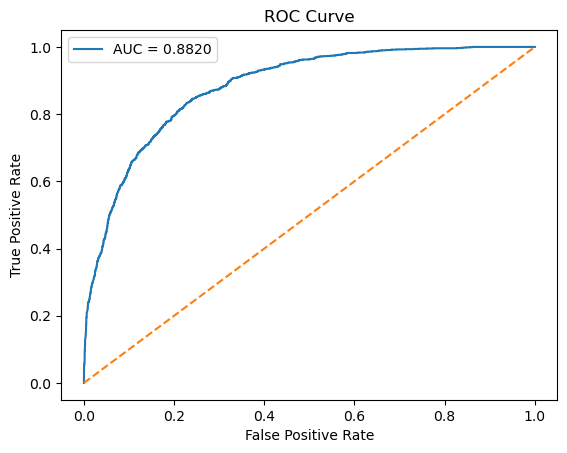

In [187]:
plot_classification_curves(gbm, X_train_std, y_train)

In [188]:
std_2 = StandardScaler()

X_train_rs_std = std_2.fit_transform(X_train_rs)
X_test_rs_std = std_2.transform(X_test)

In [189]:
gbm2 = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train
gbm2.fit(X_train_rs_std, y_train_rs)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [190]:
score(gbm2.predict(X_train_rs_std), y_train_rs)

Accuracy: 0.8078672732138079
Precision: 0.7677463818056512
Recall: 0.7451505016722408
F-1 Score: 0.7562797012898846
ROC, AUC Score: 0.7974191402205986


In [191]:
score(gbm2.predict(X_test_rs_std), y_test)

Accuracy: 0.7882018479033405
Precision: 0.5848214285714286
Recall: 0.7005347593582888
F-1 Score: 0.6374695863746959
ROC, AUC Score: 0.7602383380528134


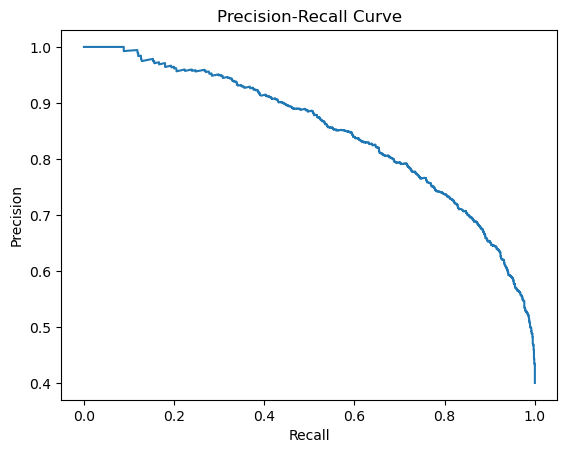

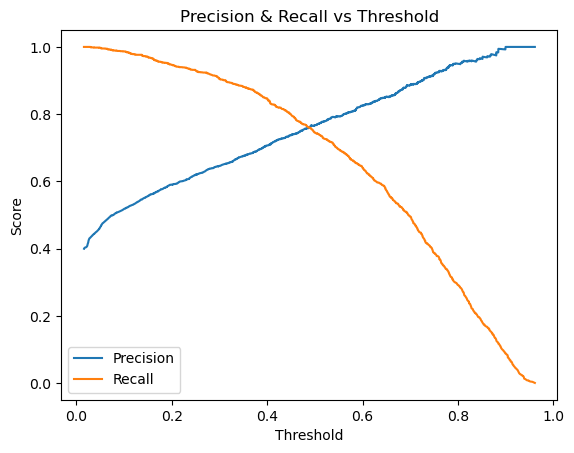

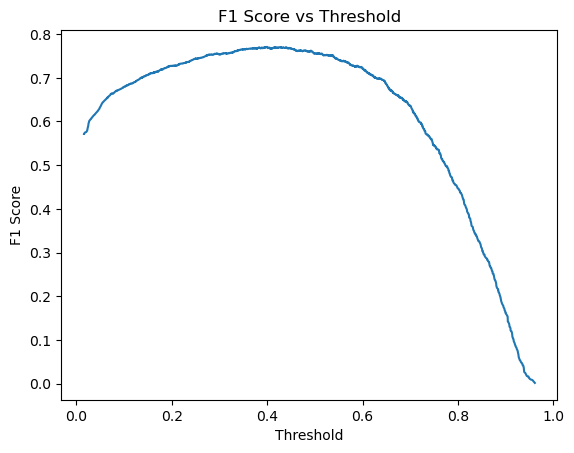

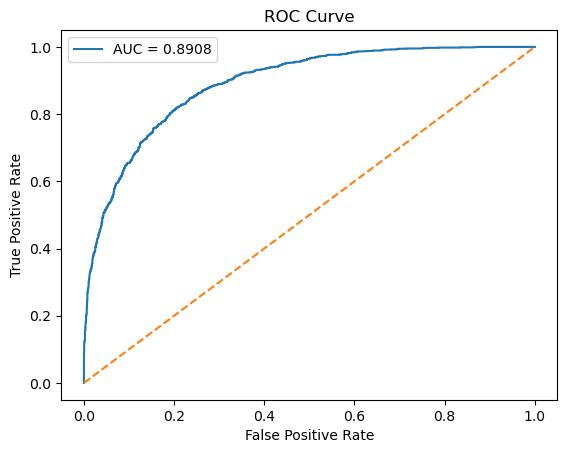

In [192]:
plot_classification_curves(gbm2, X_train_rs_std, y_train_rs)

In [193]:
# For now our best gbm model would be


best_gbm = gbm

In [194]:
feature_importance = pd.Series(best_gbm.feature_importances_, index=X.columns)
feature_importance = feature_importance.sort_values(ascending=False)

<Axes: >

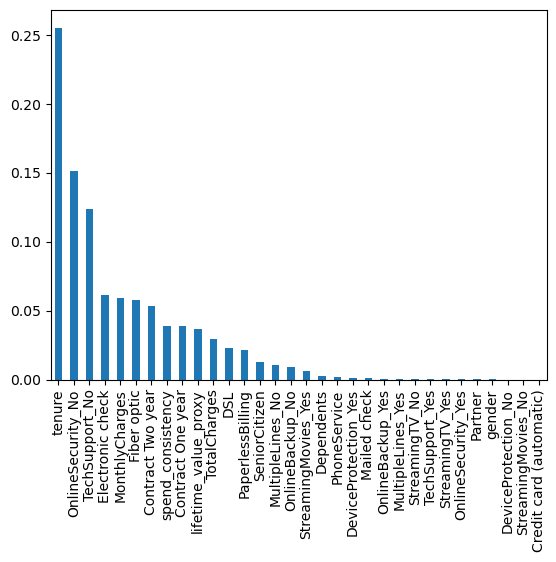

In [195]:
feature_importance.plot.bar()

In [196]:
# From here also we can see tenure, OnlineSecurity, Techsupport No, Total CHarges, Monthly Charges, Fibre optic play a huge role in the prediction

In [197]:
best_rf # This model has good accuracy, decent recall

,n_estimators,200
,criterion,'gini'
,max_depth,7
,min_samples_split,2
,min_samples_leaf,10
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [198]:
score(best_rf.predict(X_train), y_train)

Accuracy: 0.8065777777777777
Precision: 0.6141334828939988
Recall: 0.7324414715719063
F-1 Score: 0.6680902989627822
ROC, AUC Score: 0.7829277575777207


In [199]:
score(best_rf.predict(X_test), y_test)

Accuracy: 0.7910447761194029
Precision: 0.5930232558139535
Recall: 0.6818181818181818
F-1 Score: 0.6343283582089553
ROC, AUC Score: 0.7562043474434568


In [201]:
rf_bal # This model has good recall, decent accuracy

,n_estimators,200
,criterion,'gini'
,max_depth,7
,min_samples_split,2
,min_samples_leaf,10
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [202]:
score(rf_bal.predict(X_train_rs), y_train_rs)

Accuracy: 0.7795022745517795
Precision: 0.6712608473711077
Recall: 0.8795986622073578
F-1 Score: 0.7614360162130863
ROC, AUC Score: 0.7961775648235718


In [203]:
score(rf_bal.predict(X_test), y_test)

Accuracy: 0.7313432835820896
Precision: 0.4969512195121951
Recall: 0.8716577540106952
F-1 Score: 0.6330097087378641
ROC, AUC Score: 0.7760999321844377


In [204]:
# We will go with best rf ahead

In [205]:
# Now coming to feature analysis

# tenure, Online Security No, Tech Support No, Fibre Optic, Paperlessbilling
# engineerd features
# Monthly Charges, Total Charges
# Contrcat 

# Strongly inflence models' decision.

In [ ]:
# Now lets fine tune our threshold

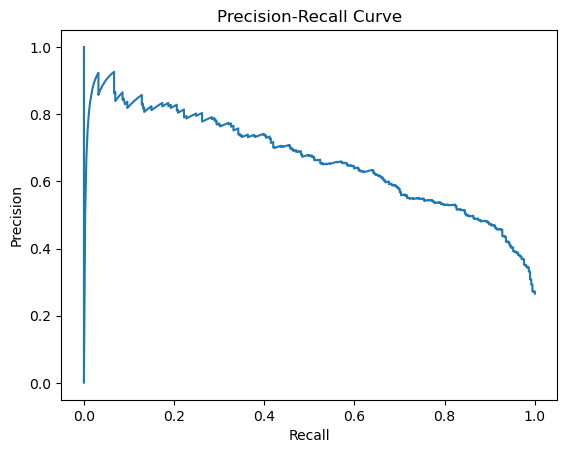

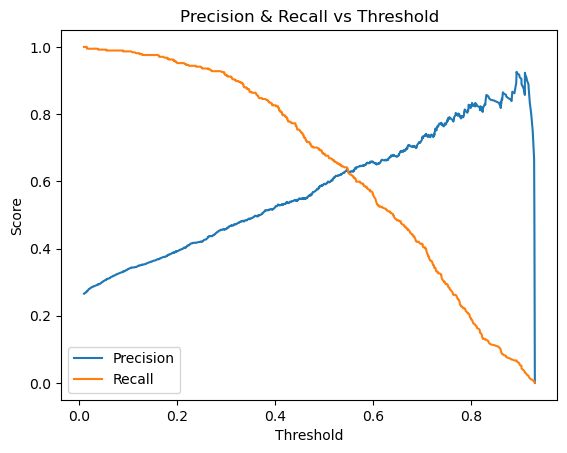

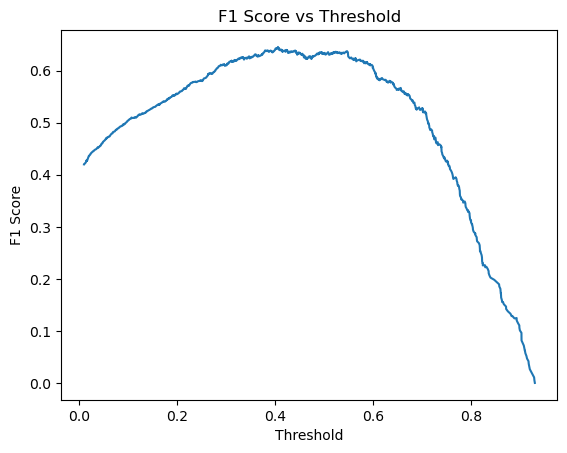

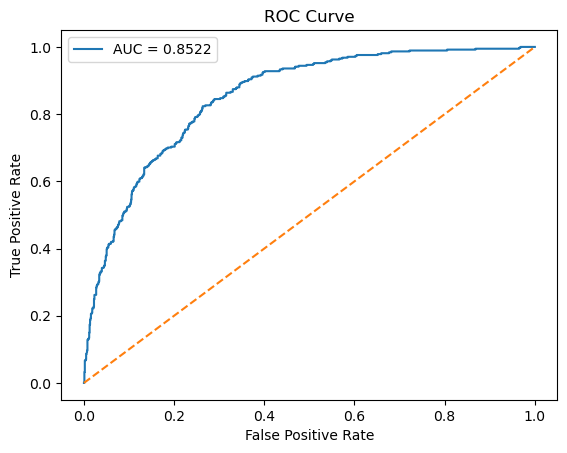

In [206]:
plot_classification_curves(best_rf, X_test, y_test)

In [207]:
# Tuning the threshold woulnt help us that much
# as our precision would be close 50 basically there would be only 50% chance that the predicted input will be a churnb
# but still lets move it to 0.45

array([1, 0, 0, ..., 0, 0, 0], shape=(1407,))

In [213]:
score((best_rf.predict_proba(X_test)[:, 1] >= 0.47).astype('int'), y_test)

Accuracy: 0.7739872068230277
Precision: 0.5583333333333333
Recall: 0.7165775401069518
F-1 Score: 0.6276346604215457
ROC, AUC Score: 0.7556750236836792


In [214]:
score((best_rf.predict_proba(X_train)[:, 1] >= 0.47).astype('int'), y_train)

Accuracy: 0.8030222222222222
Precision: 0.5997937080969572
Recall: 0.7779264214046823
F-1 Score: 0.6773442050087362
ROC, AUC Score: 0.7950164794674741


In [215]:
# 0.47 will be a valid threshold

import pickle

# Assuming 'model' is your trained machine learning model
filename = 'trained_model.pkl'

# Save the model to a file
with open(filename, 'wb') as file:
    pickle.dump(best_rf, file)

print(f"Model saved to {filename}")


Model saved to trained_model.pkl


In [217]:
df.to_csv('cleaned_data.csv', index=False)